**If you want to test it, you can use the [website](https://airbnb-prediction-app.herokuapp.com/) to see some predictions **

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import FastMarkerCluster
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)


%matplotlib inline



import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/ab-ny-august-2019/listings.csv
/kaggle/input/new-york-city-airbnb-open-data/AB_NYC_2019.csv
/kaggle/input/new-york-city-airbnb-open-data/New_York_City_.png


## Data Handling

In [ ]:
# GOOGLE COLAB DATASET UPLOAD
from google.colab import files
uploaded = files.upload()

# Upload BOTH required CSV files:
# 1) AB_NYC_2019.csv
# 2) listings.csv

airbnb_file = next((name for name in uploaded if "AB_NYC_2019" in name), None)
listings_file = next((name for name in uploaded if name.lower().endswith("listings.csv")), None)

if airbnb_file is None:
    raise FileNotFoundError("Please upload AB_NYC_2019.csv")
if listings_file is None:
    raise FileNotFoundError("Please upload listings.csv")

df = pd.read_csv(airbnb_file, index_col="id")
listings = pd.read_csv(listings_file, index_col="id")

print("Airbnb dataset:", df.shape)
print("Listings dataset:", listings.shape)


/opt/conda/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3063: DtypeWarning: Columns (61,62,94,95) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [ ]:
df.head()

,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
id,,,,,,,,,,,,,,,
2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
listings.head()

,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,notes,...,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
id,,,,,,,,,,,,,,,,,,,,,
2595,https://www.airbnb.com/rooms/2595,20190806030549,2019-08-07,Skylit Midtown Castle,"Find your romantic getaway to this beautiful, ...","- Spacious (500+ft²), immaculate and nicely fu...","Find your romantic getaway to this beautiful, ...",none,Centrally located in the heart of Manhattan ju...,NaN,...,f,f,strict_14_with_grace_period,t,t,2,1,0,1,0.39
3647,https://www.airbnb.com/rooms/3647,20190806030549,2019-08-06,THE VILLAGE OF HARLEM....NEW YORK !,NaN,WELCOME TO OUR INTERNATIONAL URBAN COMMUNITY T...,WELCOME TO OUR INTERNATIONAL URBAN COMMUNITY T...,none,NaN,NaN,...,f,f,strict_14_with_grace_period,t,t,1,0,1,0,NaN
3831,https://www.airbnb.com/rooms/3831,20190806030549,2019-08-06,Cozy Entire Floor of Brownstone,Urban retreat: enjoy 500 s.f. floor in 1899 br...,Greetings! We own a double-duplex brownst...,Urban retreat: enjoy 500 s.f. floor in 1899 br...,none,Just the right mix of urban center and local n...,NaN,...,f,f,moderate,f,f,1,1,0,0,4.64
5022,https://www.airbnb.com/rooms/5022,20190806030549,2019-08-06,Entire Apt: Spacious Studio/Loft by central park,NaN,Loft apartment with high ceiling and wood floo...,Loft apartment with high ceiling and wood floo...,none,NaN,NaN,...,f,f,strict_14_with_grace_period,t,t,1,1,0,0,0.10
5099,https://www.airbnb.com/rooms/5099,20190806030549,2019-08-06,Large Cozy 1 BR Apartment In Midtown East,My large 1 bedroom apartment is true New York ...,I have a large 1 bedroom apartment centrally l...,My large 1 bedroom apartment is true New York ...,none,My neighborhood in Midtown East is called Murr...,Read My Full Listing For All Information. New ...,...,f,f,strict_14_with_grace_period,t,t,1,1,0,0,0.60


Let's merge the datasets to use the additional information comes from the listings.csv

In [ ]:
target_columns = ["property_type", "accommodates",  "review_scores_value", "review_scores_cleanliness", "review_scores_location", "review_scores_accuracy", "review_scores_communication", "review_scores_checkin", "review_scores_rating", "maximum_nights", "host_is_superhost", "host_response_time", "host_response_rate",  'bathrooms', 'bedrooms', 'beds']
data = pd.merge(df, listings[target_columns], on='id', how='left')
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 48895 entries, 2539 to 36487245
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   name                            48879 non-null  object 
 1   host_id                         48895 non-null  int64  
 2   host_name                       48874 non-null  object 
 3   neighbourhood_group             48895 non-null  object 
 4   neighbourhood                   48895 non-null  object 
 5   latitude                        48895 non-null  float64
 6   longitude                       48895 non-null  float64
 7   room_type                       48895 non-null  object 
 8   price                           48895 non-null  int64  
 9   minimum_nights                  48895 non-null  int64  
 10  number_of_reviews               48895 non-null  int64  
 11  last_review                     38843 non-null  object 
 12  reviews_per_month         

In [ ]:
data.isnull().sum()

name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
property_type                      3371
accommodates                       3371
review_scores_value               12629
review_scores_cleanliness         12594
review_scores_location            12631
review_scores_accuracy            12611
review_scores_communication       12605
review_scores_checkin             12627
review_scores_rating              12573
maximum_nights                     3371


In [ ]:
data.describe()

,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,accommodates,...,review_scores_cleanliness,review_scores_location,review_scores_accuracy,review_scores_communication,review_scores_checkin,review_scores_rating,maximum_nights,bathrooms,bedrooms,beds
count,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000,45524.000000,...,36301.000000,36264.000000,36284.000000,36290.000000,36268.000000,36322.000000,4.552400e+04,45470.000000,45503.000000,45487.000000
mean,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327,2.823851,...,9.286025,9.569683,9.630057,9.763544,9.754632,94.011150,4.869897e+04,1.141115,1.166297,1.536989
std,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289,1.843100,...,1.070661,0.754216,0.827604,0.713807,0.706209,8.434653,1.006577e+07,0.427321,0.732174,1.097193
min,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000,1.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,20.000000,1.000000e+00,0.000000,0.000000,0.000000
25%,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000,2.000000,...,9.000000,9.000000,9.000000,10.000000,10.000000,92.000000,2.900000e+01,1.000000,1.000000,1.000000
50%,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000,2.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,96.000000,1.111000e+03,1.000000,1.000000,1.000000
75%,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000,4.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,100.000000,1.125000e+03,1.000000,1.000000,2.000000
max,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000,19.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,100.000000,2.147484e+09,15.500000,14.000000,40.000000


### Handling Missing Data

1.   The **weekly price** and the **monthly price** columns are mostly missing. We can drop it.
2.   We can fullfill the **reviews_per_month** just dividing **number reviews** by 12.

3. Since there is not much standart deviation we can fullfill the **review_scores** with it's mean.

4. We can fullfill the **response time** with the mean value

5. The other object columns can be filled the most occurring element in that column.

6. Badrooms, Bed, Bathroom can be replaced with it's mean

In [ ]:
data['reviews_per_month'] = data['number_of_reviews'] / 12

reviews = ['review_scores_value', 'review_scores_cleanliness', 'review_scores_location', 'review_scores_accuracy', 'review_scores_communication', 'review_scores_checkin', 'review_scores_rating']
for i in reviews:
  data[i].fillna(data[i].mean(), inplace=True)

data['accommodates'].fillna(data['accommodates'].mean(), inplace=True)
data['maximum_nights'].fillna(data['maximum_nights'].mean(), inplace=True)

data.drop(columns=['last_review'], inplace=True)

cat_columns = ['host_response_time', 'host_response_rate', 'property_type', 'host_is_superhost']

for i in cat_columns:
  data[i].fillna(data[i].value_counts().idxmax(), inplace=True)

a = ['bathrooms', 'beds', 'bedrooms']
for i in a:
  data[i].fillna(data[i].mean(), inplace=True)


data.isnull().sum()


name                              16
host_id                            0
host_name                         21
neighbourhood_group                0
neighbourhood                      0
latitude                           0
longitude                          0
room_type                          0
price                              0
minimum_nights                     0
number_of_reviews                  0
reviews_per_month                  0
calculated_host_listings_count     0
availability_365                   0
property_type                      0
accommodates                       0
review_scores_value                0
review_scores_cleanliness          0
review_scores_location             0
review_scores_accuracy             0
review_scores_communication        0
review_scores_checkin              0
review_scores_rating               0
maximum_nights                     0
host_is_superhost                  0
host_response_time                 0
host_response_rate                 0
b

### Handling Outliers


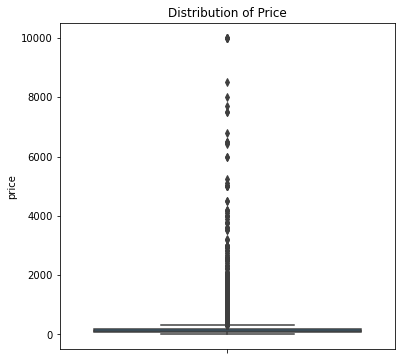

In [ ]:
plt.figure(figsize=(6,6))
sns.boxplot(y=data['price'])
plt.title("Distribution of Price")
plt.show()

There are so many outlier in the price. Let's drop them.

In [ ]:
mean = data['price'].mean()
std = data['price'].std()
upper_limit = mean + 3 * std
data = data[data['price'] <= upper_limit]

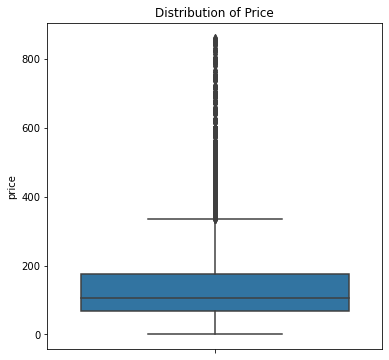

In [ ]:
plt.figure(figsize=(6,6))
sns.boxplot(y=data['price'])
plt.title("Distribution of Price")
plt.show()

In [ ]:
data.head()

,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,...,review_scores_communication,review_scores_checkin,review_scores_rating,maximum_nights,host_is_superhost,host_response_time,host_response_rate,bathrooms,bedrooms,beds
id,,,,,,,,,,,,,,,,,,,,,
2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,...,9.763544,9.754632,94.01115,48698.973355,f,within an hour,100%,1.141115,1.166297,1.536989
2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,...,10.000000,10.000000,95.00000,1125.000000,f,within a few hours,90%,1.000000,0.000000,1.000000
3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,...,9.763544,9.754632,94.01115,7.000000,f,within a day,100%,1.000000,1.000000,1.000000
3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,...,9.000000,10.000000,90.00000,730.000000,f,within an hour,90%,1.000000,1.000000,4.000000
5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,...,10.000000,10.000000,93.00000,120.000000,f,within an hour,100%,1.000000,1.166297,1.000000


**What's Done**


1.   Handling the Missing Values
2.   Dropping the Outliers



## DATA EXPLORATION

In this section what we will do:

*   Visualization of Some Columns
*   Understand if There is a Correlation Between tthe Variables
*   Understand the behaviour the data


### Neighbourhood Distribution

Text(0.5, 1.0, 'Numbers in Each Neigbourhoods')

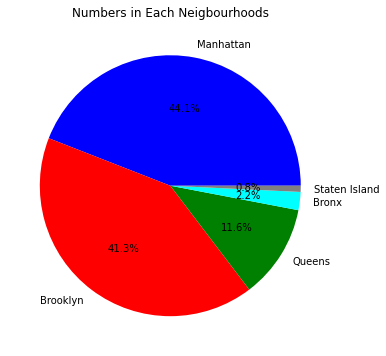

In [ ]:
plt.figure(figsize=(6,6))
numbers = data['neighbourhood_group'].value_counts()
plt.pie(numbers.values, labels=numbers.index, colors=['b', 'r', 'g', 'cyan', 'gray'], autopct='%1.1f%%')
plt.title('Numbers in Each Neigbourhoods')

Manhattan has the most house. Brooklyn follows Manhattan with a big portion. Mostly the rooms are distributed in Brooklyn and Manhattan

### Room Type Distribution

Text(0.5, 1.0, 'Numbers in Each Room Types')

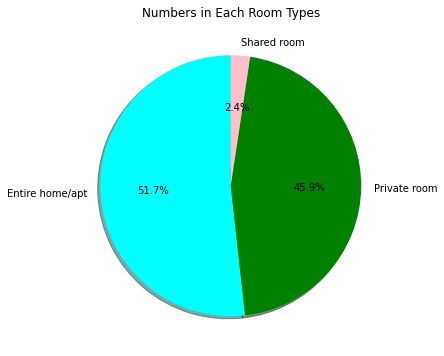

In [ ]:
plt.figure(figsize=(6,6))
numbers = data['room_type'].value_counts()
plt.pie(numbers.values, labels=numbers.index, colors=['cyan', 'green', 'pink'], autopct='%1.1f%%', shadow=True,startangle=90)
plt.title('Numbers in Each Room Types')

There are mostly entire home and private room. There is also a small portion in shared rooms.

### Distribution of room types in the Map.

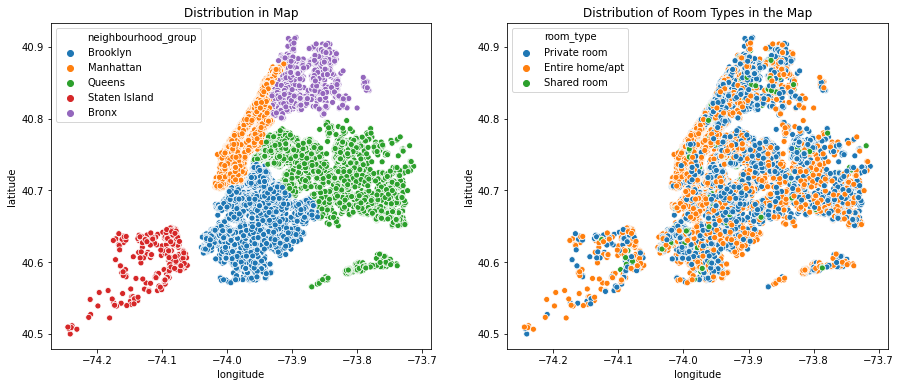

In [ ]:
fig = plt.figure(figsize=(15,6))

ax1 = fig.add_subplot(121)
sns.scatterplot(data['longitude'], data['latitude'], hue=data['neighbourhood_group'], ax=ax1)
ax1.set_title('Distribution in Map')

ax2 = fig.add_subplot(122)
sns.scatterplot(data['longitude'], data['latitude'], hue=data['room_type'], ax=ax2)
ax2.set_title('Distribution of Room Types in the Map')

plt.show()

### Distribution of Room Types in Each Neighbourhood

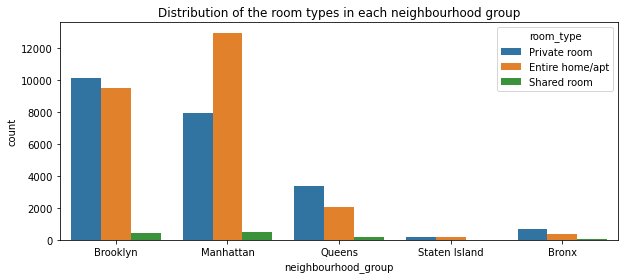

In [ ]:
plt.figure(figsize=(10,4))
sns.countplot(data['neighbourhood_group'], hue=data['room_type'])
plt.title('Distribution of the room types in each neighbourhood group')
plt.show()

Manhattan has the most room. Mostly the room types in Manhattan is Entire Home which is an interesting part. Because in the other neighbourhoods, the private room number is higher than the entire home.

In [ ]:
### Price Distribution in Each Neighbourhood

Text(0, 0.5, 'Price')

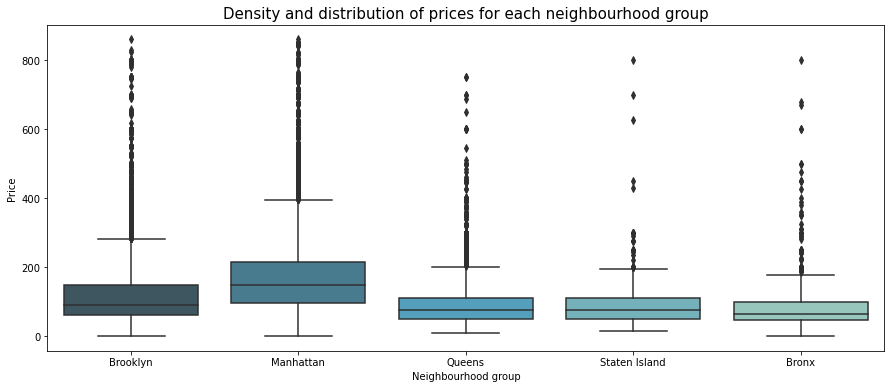

In [ ]:
plt.figure(figsize=(15,6))
sns.boxplot(data=data, x='neighbourhood_group', y='price', palette='GnBu_d')
plt.title('Density and distribution of prices for each neighbourhood group', fontsize=15)
plt.xlabel('Neighbourhood group')
plt.ylabel("Price")

It can be seen that mean of prices in **Manhattan** are higher than the rest. Let' see which room is the most expensive and which room type is the cheapest.

### Price Distribution in Each Room Type

Text(0, 0.5, 'Price')

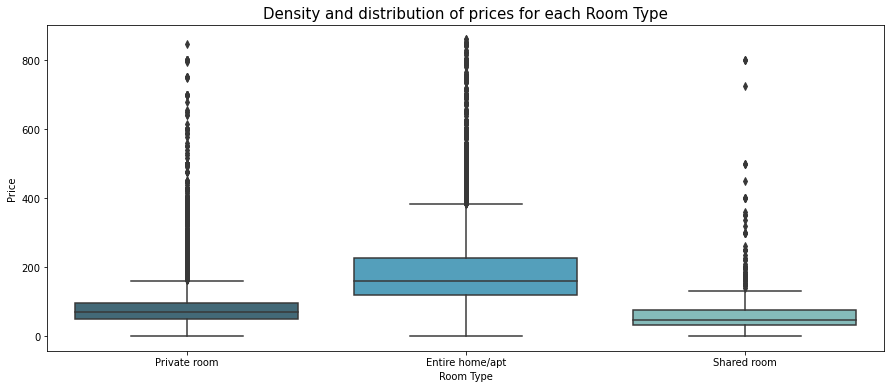

In [ ]:
plt.figure(figsize=(15,6))
sns.boxplot(data=data, x='room_type', y='price', palette='GnBu_d')
plt.title('Density and distribution of prices for each Room Type', fontsize=15)
plt.xlabel('Room Type')
plt.ylabel("Price")

It is not an unusual condition. It makes sense that entire home is more expensive than other and it also makes sense that private room is more expensive than the shared room.

One of the reason **Manhattan is more expensive than others** might be the **room type**. We already know that **entire homes** are **more expensive** than others. Manhattan has the most entire home room type.

### Distribution of the Rooms in the Map

Credits to:  [Erik Bruin](https://www.kaggle.com/erikbruin/airbnb-the-amsterdam-story-with-interactive-maps)

In [ ]:
latitudes = np.array(data['latitude'])
longitudes = np.array(data['longitude'])
la_mean = latitudes.mean()
lo_mean = longitudes.mean()
locations = list(zip(latitudes, longitudes))

m = folium.Map(location=[la_mean, lo_mean], zoom_start= 11.5)
FastMarkerCluster(data=locations).add_to(m)
m

### Distribution of the Accommodates

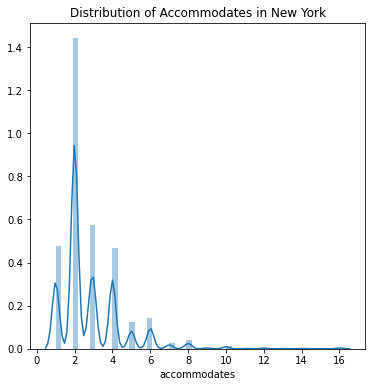

In [ ]:
plt.figure(figsize=(6, 6))
sns.distplot(data['accommodates'])
plt.title('Distribution of Accommodates in New York')
plt.show()

Mostly houses are 2 accommodates

### Distribution of the Price

Text(0.5, 1.0, 'Distribution of price')

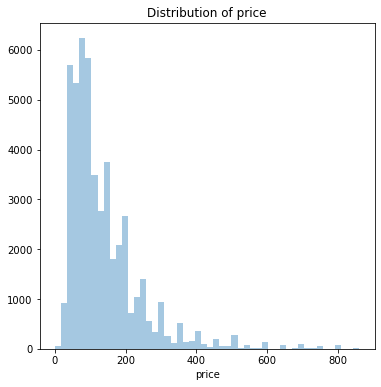

In [ ]:
plt.figure(figsize=(6, 6))
sns.distplot(data['price'], kde=False)
plt.title('Distribution of price')

It can be seen that prices are mostly around between 100 and 200 dollars.
Price data is right skewed. Let's plot the Price Distribution in Logarithm to see what happens

Text(0.5, 1.0, 'Distribution of price in Logarithm')

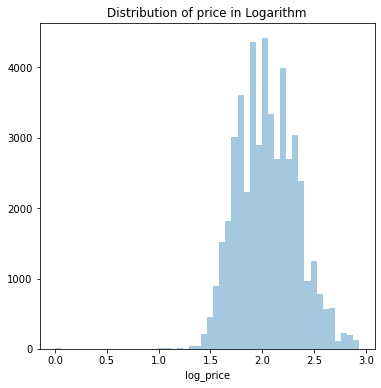

In [ ]:
data['log_price'] = np.log10(data['price'] + 1)
plt.figure(figsize=(6, 6))
sns.distplot(data['log_price'], kde=False)
plt.title('Distribution of price in Logarithm')

When we plot the price in logarithmic case, the distribution likes the normal distribution. The skewed data turned to like a normal distribution.

### Most Expensive and The Cheapest Neighbourhoods

In [ ]:
a = data.groupby('neighbourhood')['price'].mean().sort_values(ascending=True).head(20)
d = data.groupby('neighbourhood')['price'].mean().sort_values(ascending=False).head(20)

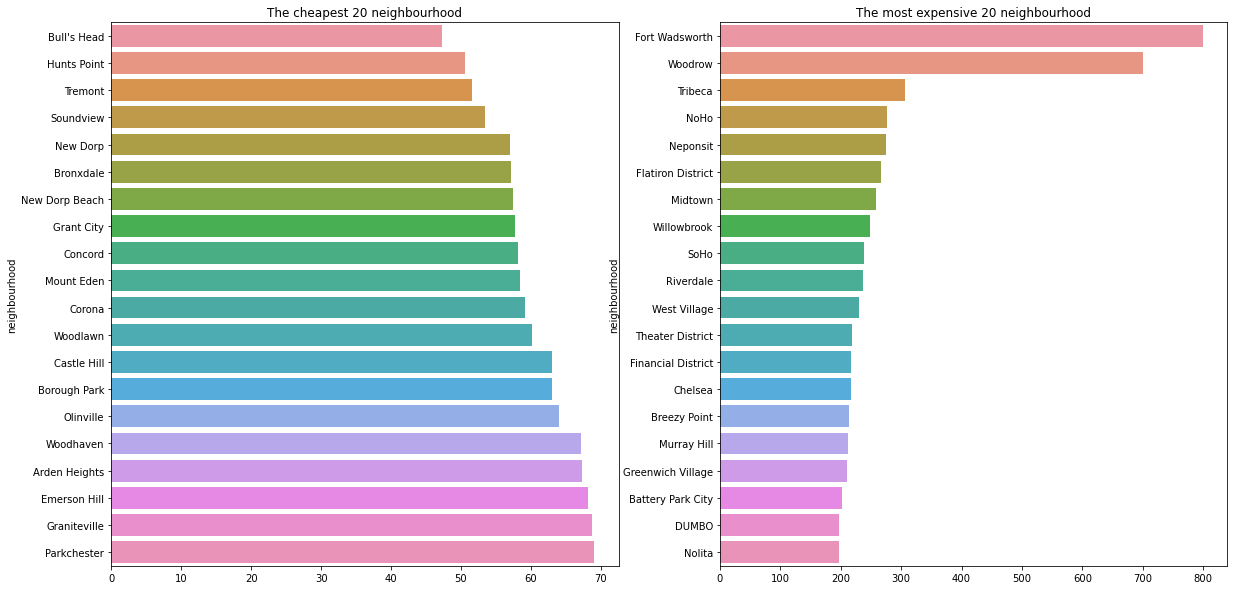

In [ ]:
fig = plt.figure(figsize=(20,10))

ax1 = fig.add_subplot(121)
sns.barplot(y=a.index, x=a.values, ax=ax1)
ax1.set_title('The cheapest 20 neighbourhood')

ax2 = fig.add_subplot(122)
sns.barplot(y=d.index, x=d.values, ax=ax2)
ax2.set_title('The most expensive 20 neighbourhood')
plt.show()

### Distribution of the Reviews

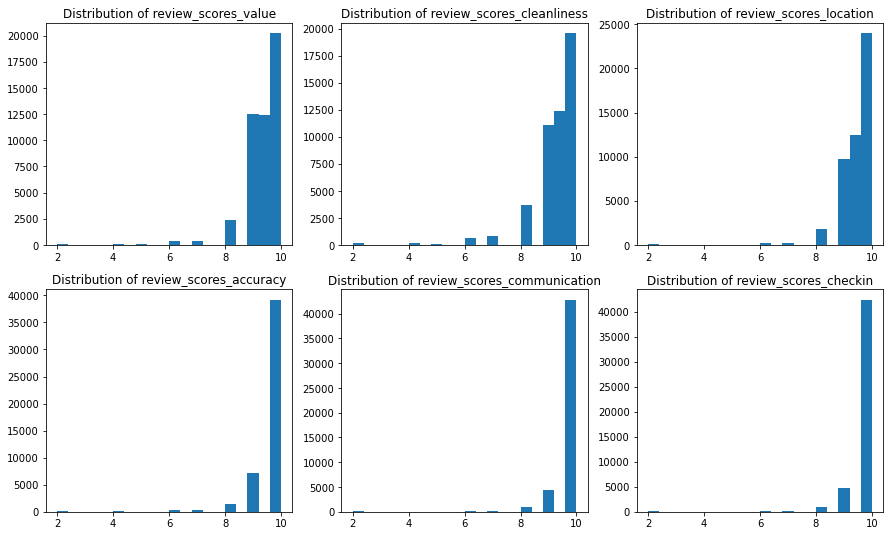

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9))

for ax, name in zip(axes.flatten(), reviews):
  ax.hist(data[name], bins=20)
  ax.set_title(f"Distribution of {name}")

plt.show()



Reviews Scores are mostly around 8 - 10. Since the most of the houses review scores are high, it might not be a good feature for price prediction. But that is just an assumption. We will see if there is a correlation between review scores and the price after a few cells.

### Distribution of the Rooms

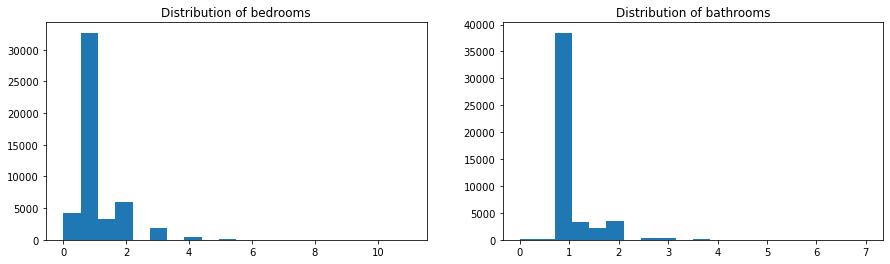

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 4))

rooms = ['bedrooms', 'bathrooms']

for ax, name in zip(axes.flatten(), rooms):
  ax.hist(data[name], bins=20)
  ax.set_title(f"Distribution of {name}")

plt.show()


The distribution builds up around 1. This means in an average home there is one room and 1 bathroom.

### Distribution of Availability

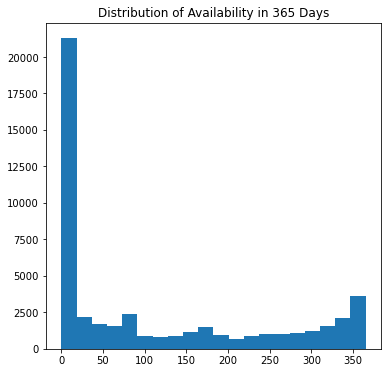

In [ ]:
plt.figure(figsize=(6,6))

plt.hist(data['availability_365'], bins=20)

plt.title("Distribution of Availability in 365 Days")

plt.show()

There are every kind of information in our dataset. There is 365 day, there is 0 day also. The data is right skewed.

### Correlation Map Between Numerical Variables

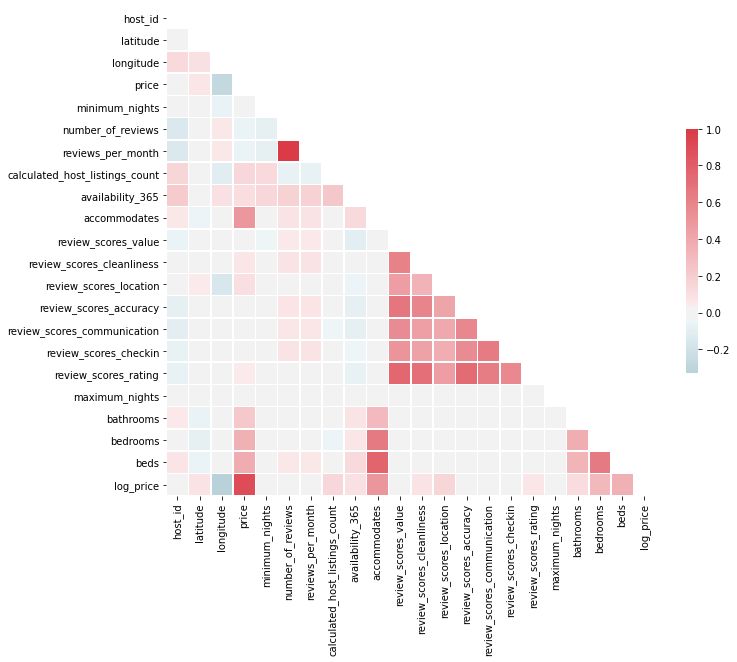

In [ ]:
corr = data.corr()
mask = np.triu(np.ones_like(corr, dtype=np.bool))
f, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

It can be seen that there is a strong correlation in the reviews part. But there is no strong correlation between reviews scores and prices. Because most of the host's review scores are between 8 - 10. However, there is a strong correlation between (bedrooms, bathrooms and bed) and price.

### Correlation Graphics Between Each Column and the Price

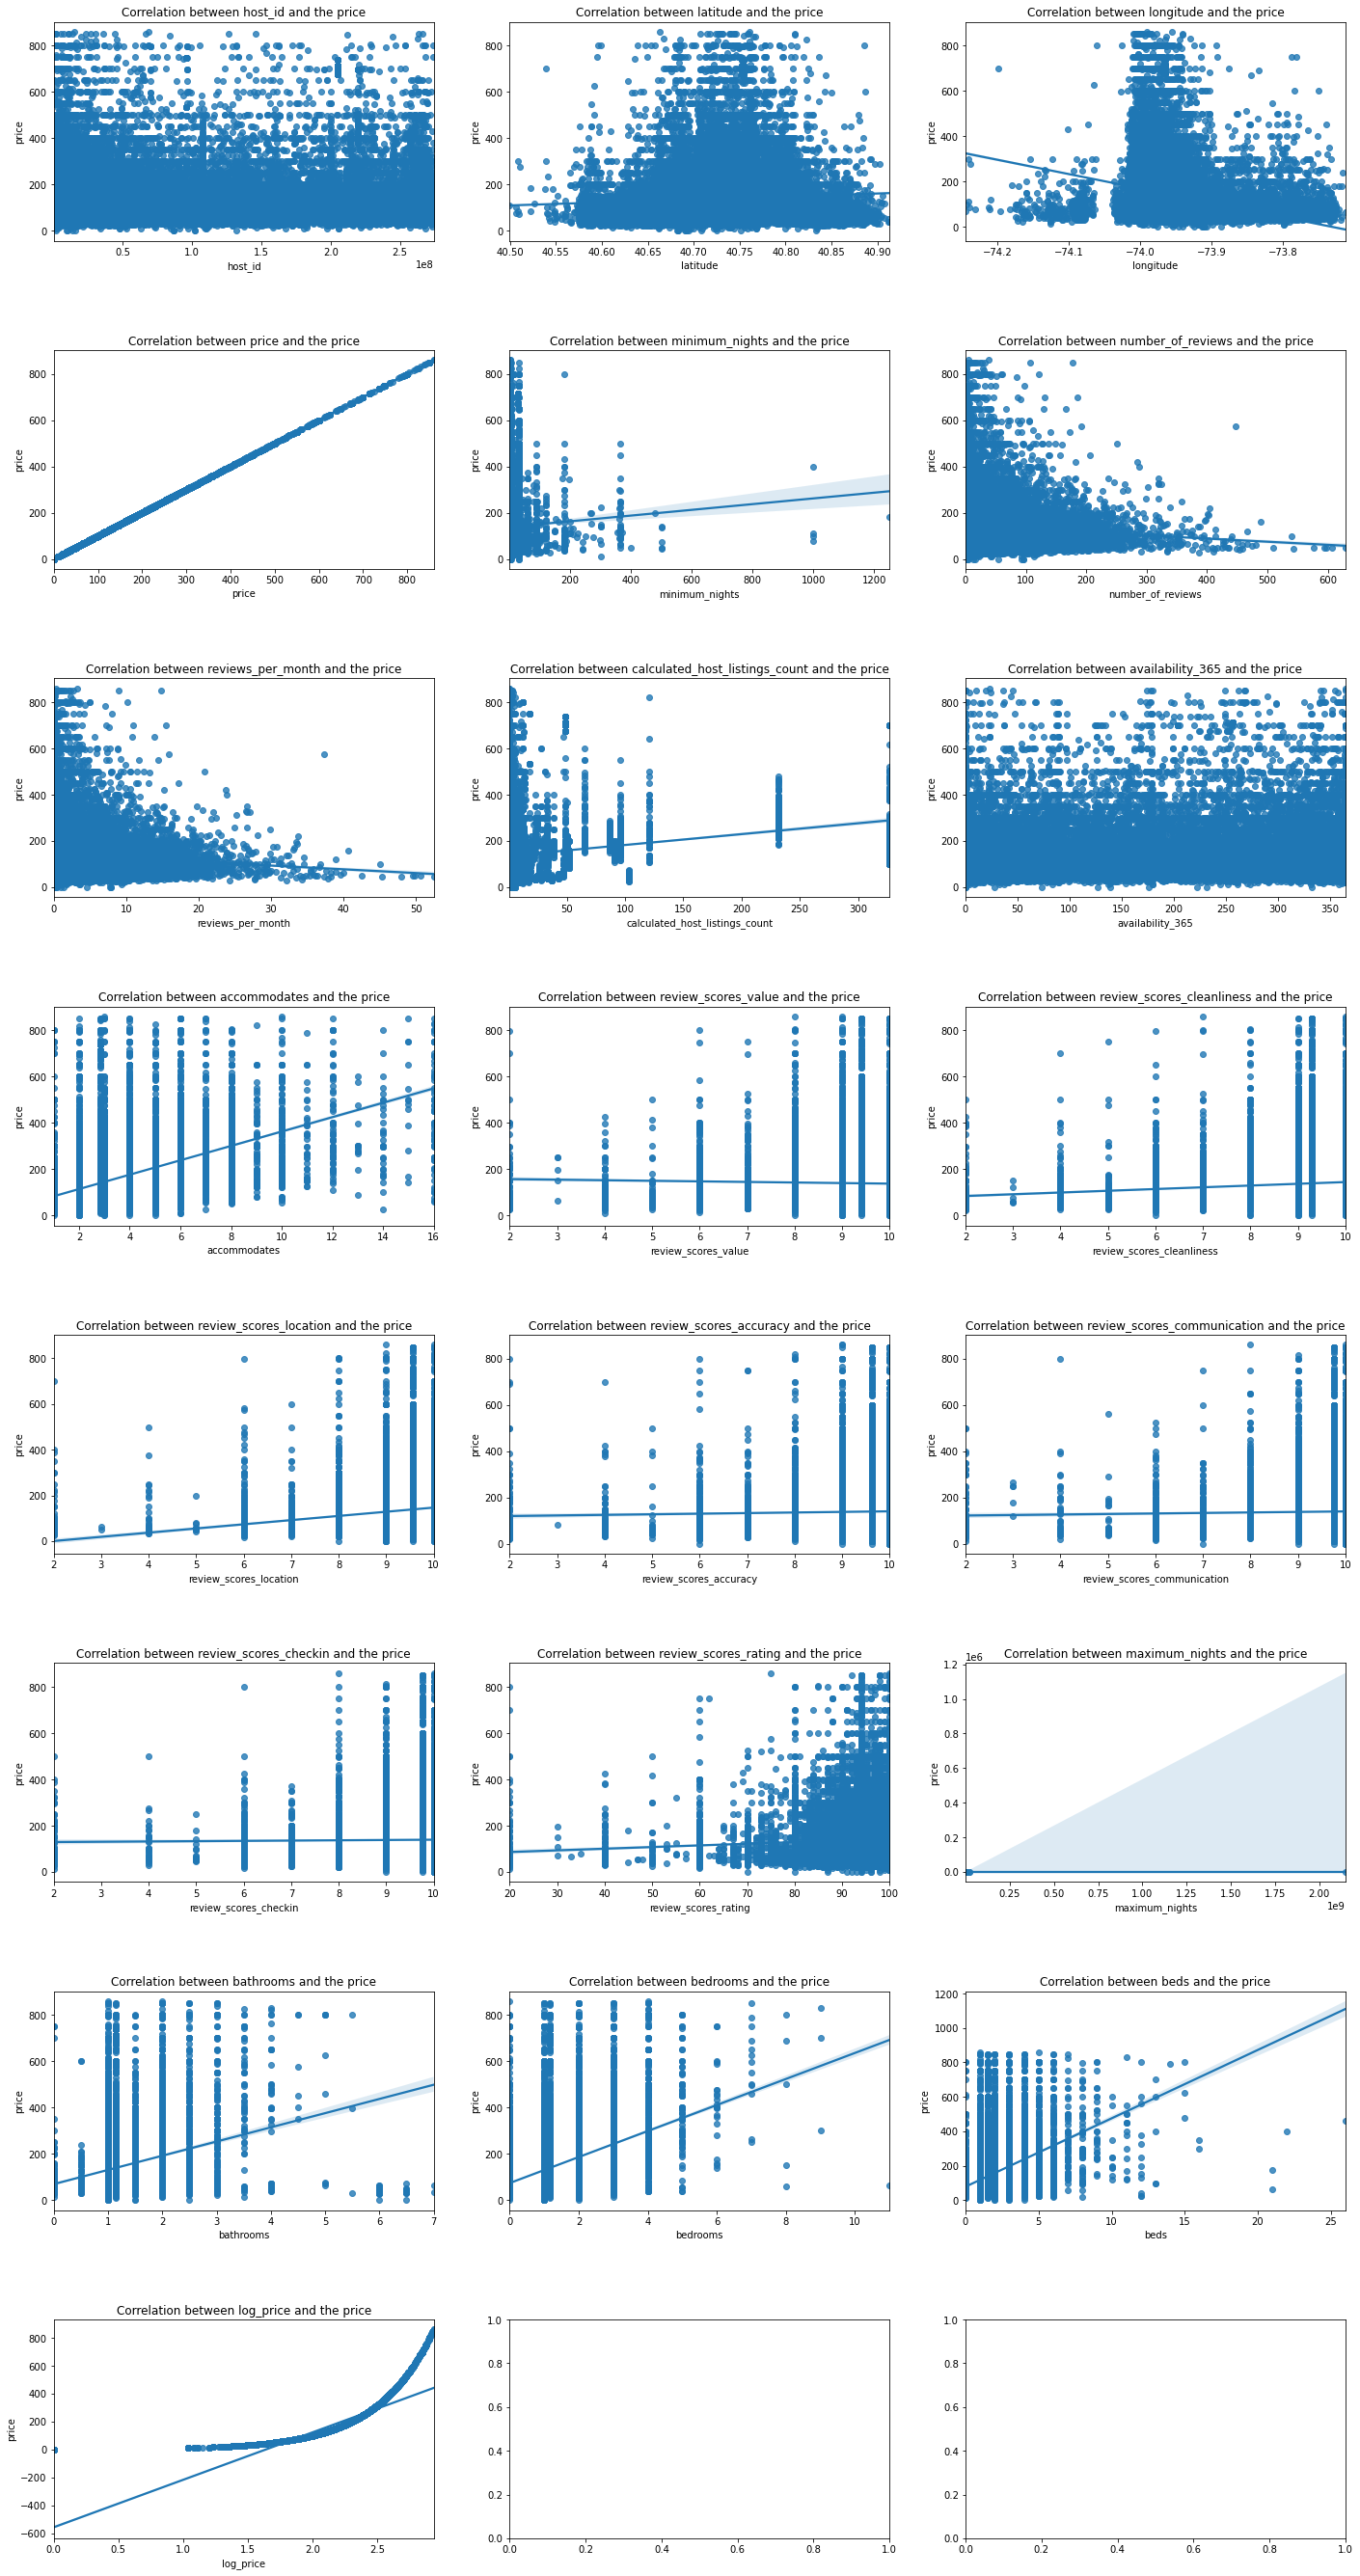

In [ ]:
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']

newdf = data.select_dtypes(include=numerics)
nrows = int(len(newdf.columns) / 3) + 1
fig, axes = plt.subplots(nrows=nrows, ncols=3, figsize=(24, 6*nrows))
fig.subplots_adjust(hspace=0.5)

for ax, name in zip(axes.flatten(), newdf.columns):

  sns.regplot(x=name, y='price', data=newdf, ax=ax)
  ax.set_title(f"Correlation between {name} and the price")

plt.show()

There is a relationships between **accommodates** and the **price.** It can be seen easily above 2 parts. It is natural to have that kind of correlation. Because, when the number of people that can stay in a place, the price will increase naturally. And the there is a correlation between **some of the review scores and the prices.** There is also a correlation between **bathrooms, bathrooms and bed, to price.** There is also a **negative correlation between distance to nearest station and the price.** When the distance increases, the price decreases. We already know that, the shorter distance is an important feature for the houses nowadays.

### Distrbution of None Numerical Columns

In [ ]:
a = data.groupby(['neighbourhood_group', 'neighbourhood'])['price'].mean().sort_values(ascending=False).head(50)
a = a.reset_index()
a

,neighbourhood_group,neighbourhood,price
0,Staten Island,Fort Wadsworth,800.000000
1,Staten Island,Woodrow,700.000000
2,Manhattan,Tribeca,305.792453
3,Manhattan,NoHo,276.246753
4,Queens,Neponsit,274.666667
5,Manhattan,Flatiron District,266.053333
6,Manhattan,Midtown,258.347682
7,Staten Island,Willowbrook,249.000000
8,Manhattan,SoHo,238.526316
9,Bronx,Riverdale,236.300000


Credits to: [Devakumar kp](https://www.kaggle.com/imdevskp/nyc-airbnb-open-data-eda)

[]

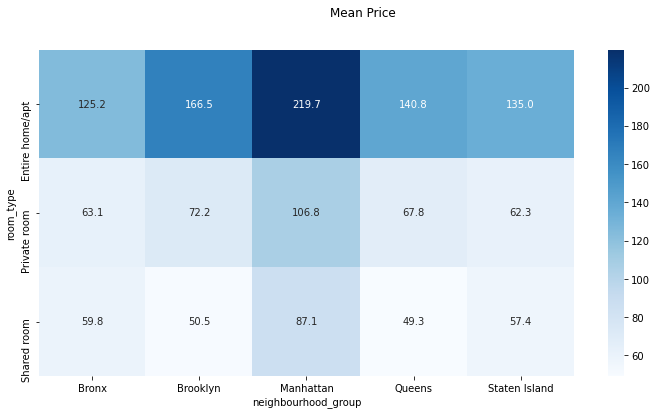

In [ ]:
plt.figure(figsize=(12, 6))
df_pivot = data.pivot_table(values='price', index='room_type', columns='neighbourhood_group', aggfunc='mean')
sns.heatmap(df_pivot, annot=True, fmt='.1f', cmap='Blues')
plt.suptitle('Mean Price')
plt.plot()

**It can be seen that in every neighbourhood price of Entire Home > Private Room > Shared Room.**

In [ ]:
a = data.groupby(['neighbourhood_group', 'property_type'])['price'].mean().sort_values(ascending=False).head(20)
a = a.reset_index()
a

,neighbourhood_group,property_type,price
0,Manhattan,Lighthouse,750.000000
1,Manhattan,Villa,470.000000
2,Manhattan,Resort,465.031746
3,Queens,Houseboat,365.000000
4,Manhattan,Cabin,300.000000
5,Bronx,Villa,299.000000
6,Manhattan,Aparthotel,279.357143
7,Manhattan,Loft,277.136951
8,Manhattan,Boutique hotel,263.470000
9,Manhattan,Serviced apartment,250.229226


**Villa's, Boutique Hotel are the common property types which are expensive in every Neighbourhood Group.**

## MACHINE LEARNING

Our purpose is predict the price based on the given dataset. Since price is a continous variable we need to do a regression task. Therefore, we will use the Regression models of the traditional models such as KNN, SVM.

We are not after accuracy, because we are doing a regression task, not a classification task. Our main metric will be mean squared error and we will try to minimize it with some methods such as hyperparameter tuning.

Almost in every model we have sections such as




Before Hyperparameter Tuning( We are trying model with default



*   Train model with the default parameters

*   See the error and r2 score

*   Compare with other models and results

After Hyperparameter Tuning



*   Determine the parameter grid
*   Do a gridsearch to get best model parameters.
* Compare with the default model and other models.





### DATA PREPARATION

#### Dropping Unnecessary Columns

In [ ]:
data = data[data.price > 0]
data.columns

Index(['name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood',
       'latitude', 'longitude', 'room_type', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365', 'property_type',
       'accommodates', 'review_scores_value', 'review_scores_cleanliness',
       'review_scores_location', 'review_scores_accuracy',
       'review_scores_communication', 'review_scores_checkin',
       'review_scores_rating', 'maximum_nights', 'host_is_superhost',
       'host_response_time', 'host_response_rate', 'bathrooms', 'bedrooms',
       'beds', 'log_price'],
      dtype='object')

We will not need name, host_id, host_name. Because those columns does not affect price.

In [ ]:
data.drop(columns=['name', 'host_id', 'host_name', 'reviews_per_month'], inplace=True)

#### ENCODING

In [ ]:
data.dtypes

neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
calculated_host_listings_count      int64
availability_365                    int64
property_type                      object
accommodates                      float64
review_scores_value               float64
review_scores_cleanliness         float64
review_scores_location            float64
review_scores_accuracy            float64
review_scores_communication       float64
review_scores_checkin             float64
review_scores_rating              float64
maximum_nights                    float64
host_is_superhost                  object
host_response_time                 object
host_response_rate                 object
bathrooms                         

As we can see above the neighbourhood_group, neighbourhood, room type, host_is_superhost, host_response time and host_response rate are all categorical columns. Let's encode them, se we can use them in training.

In [ ]:
from sklearn.preprocessing import LabelEncoder

categorical = data.select_dtypes(include=['object']).columns

for i in categorical:
  data[i] = LabelEncoder().fit_transform(data[i])


data.dtypes

neighbourhood_group                 int64
neighbourhood                       int64
latitude                          float64
longitude                         float64
room_type                           int64
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
calculated_host_listings_count      int64
availability_365                    int64
property_type                       int64
accommodates                      float64
review_scores_value               float64
review_scores_cleanliness         float64
review_scores_location            float64
review_scores_accuracy            float64
review_scores_communication       float64
review_scores_checkin             float64
review_scores_rating              float64
maximum_nights                    float64
host_is_superhost                   int64
host_response_time                  int64
host_response_rate                  int64
bathrooms                         

In [ ]:
data = data.reset_index(drop=True)

data.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,...,review_scores_checkin,review_scores_rating,maximum_nights,host_is_superhost,host_response_time,host_response_rate,bathrooms,bedrooms,beds,log_price
0,1,108,40.64749,-73.97237,1,149,1,9,6,365,...,9.754632,94.01115,48698.973355,0,3,2,1.141115,1.166297,1.536989,2.176091
1,2,127,40.75362,-73.98377,0,225,1,45,2,355,...,10.000000,95.00000,1125.000000,0,2,67,1.000000,0.000000,1.000000,2.354108
2,2,94,40.80902,-73.94190,1,150,3,0,1,365,...,9.754632,94.01115,7.000000,0,1,2,1.000000,1.000000,1.000000,2.178977
3,1,41,40.68514,-73.95976,0,89,1,270,1,194,...,10.000000,90.00000,730.000000,0,3,67,1.000000,1.000000,4.000000,1.954243
4,2,61,40.79851,-73.94399,0,80,10,9,1,0,...,10.000000,93.00000,120.000000,0,3,2,1.000000,1.166297,1.000000,1.908485


Let's determine train data and target column. After that scale the data.
Split the data as:


*   Training: 80%
*   Test : 20%

In [ ]:
data.drop(columns=['log_price'], inplace=True)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = data.drop(columns=['price'])
y = data['price']

columns = X.columns
scaler = StandardScaler()
X[columns] = scaler.fit_transform(X[columns])



X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"There are {X_train.shape[0]} traning data")
print(f"There are {X_test.shape[0]} test data")


X.head()

There are 38796 traning data
There are 9700 test data


,neighbourhood_group,neighbourhood,latitude,longitude,room_type,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,property_type,...,review_scores_communication,review_scores_checkin,review_scores_rating,maximum_nights,host_is_superhost,host_response_time,host_response_rate,bathrooms,bedrooms,beds
0,-0.914773,0.014738,-1.491170,-0.441597,0.905201,-0.294649,-0.322196,-0.035443,1.925506,-0.462572,...,-0.000180,-0.000537,0.000190,-0.000033,-0.484898,0.514401,-0.451006,0.016193,0.010925,0.010177
1,0.441930,0.291191,0.452418,-0.688596,-0.928033,-0.294649,0.483588,-0.156399,1.849343,-0.462572,...,0.384208,0.403665,0.136079,-0.004912,-0.484898,-0.877153,2.365575,-0.345316,-1.686890,-0.514982
2,0.441930,-0.188964,1.466974,0.218584,0.905201,-0.196092,-0.523642,-0.186638,1.925506,-0.462572,...,-0.000180,-0.000537,0.000190,-0.005026,-0.484898,-2.268707,-0.451006,-0.345316,-0.231158,-0.514982
3,-0.914773,-0.960122,-0.801675,-0.168381,-0.928033,-0.294649,5.519735,-0.186638,0.623115,1.436938,...,-1.241412,0.403665,-0.551028,-0.004952,-0.484898,0.514401,2.365575,-0.345316,-0.231158,2.418932
4,0.441930,-0.669119,1.274501,0.173301,-0.928033,0.148858,-0.322196,-0.186638,-0.854451,-0.462572,...,0.384208,0.403665,-0.138764,-0.005015,-0.484898,0.514401,-0.451006,-0.345316,0.010925,-0.514982


### MODEL TRAINING

What has been done in this section:


1.   Trained in Various Models
2.   In Each model, we tried to minimize the mean_squared_error with using hyperparameter tuning and cross validation.
3. Showed results in each model.
4. Model comparison, (which model performed best)



#### Evalution Metrics

*MSE (mean squared error)*: $\frac{1}{N}\sum_i \, (y_{true_i} - y_{pred_i})^2 \,$


*RMSE (root mean squared error)*: $\sqrt{\frac{1}{N}\sum_i \, (y_{true_i} - y_{pred_i})^2}$


*MAE (mean absolute error)*: $\frac{1}{N} \sum_i \, |y_{true_i} - y_{pred_i}| \,$

Since we are measuring the errors, we want to **minimize** these metrics.

#### K NEAREST NEIGHBOUR

**K NEAREST NEIGHBOUR** can be used for ***regression***. But there is a better model which is **KNeighborsRegressor** which is used for regression tasks. Therefore, we will try ***KNeighborsRegressor*** for our price prediction goal.

##### BEFORE HYPERPARAMATER TUNING

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.neighbors import KNeighborsRegressor


knn = KNeighborsRegressor(5, metric="euclidean")
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

mse = mean_squared_error(y_pred, y_test)
mae = mean_absolute_error(y_pred, y_test)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error: {}".format(mse))
print("Mean Absolute Error: {}".format(mae))
print("Root Mean Absolute Error: {}".format(rmse))
print("R2 score: {}".format(r2))

Mean Squared Error: 5661.974049484536
Mean Absolute Error: 44.47074226804124
Root Mean Absolute Error: 75.24608992821179
R2 score: 0.5377570985086806


R2 score is 0.537 which means there is a correlation between the predictions and the actual values. The mean squared Error is 5661.

In [ ]:
prediction_dictionaries = {'KNN-Default': y_pred}

In [ ]:
prediction_list = pd.DataFrame({'Actual Values': np.array(y_test).flatten(), 'KNN-Default': y_pred.flatten()}).head(20)
prediction_list.set_index('Actual Values', inplace=True)
prediction_list

,KNN-Default
Actual Values,
91,144.2
325,107.6
225,225.0
145,207.8
333,162.0
49,62.4
210,387.8
110,167.0
70,180.0


In [ ]:
error_dict = {'KNN Default': [mse, r2]}
error_list = pd.DataFrame()
error_list['KNN Default'] = [mse, r2]
error_list.reset_index(inplace=True, drop=True)
#error_list.rename(columns={0: 'MSE KNN Default'}, inplace=True)
error_list.index =['Mean Squared Error', 'R2 Score']
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757


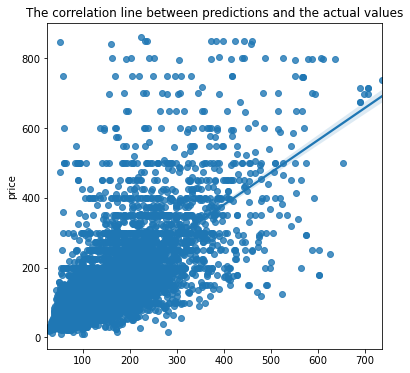

In [ ]:
plt.figure(figsize=(6,6))
sns.regplot(y_pred, y_test)
plt.title("The correlation line between predictions and the actual values")
plt.show()

In [ ]:
def plot_all_r2():
  length = len(prediction_dictionaries)
  n_col = 2
  if length < 2:
    n_col = length % 2

  nrow = 1
  if(length > 2):
    nrow = int(length / 2)
    if length % 2 != 0:
      nrow+=1

  fig, axes = plt.subplots(nrow, n_col, figsize=( 16, 3 * length))
  for ax, key in zip(axes.flatten(), prediction_dictionaries.keys()):
    sns.regplot(prediction_dictionaries[key], y_test, ax=ax)
    ax.set_title("The correlation line in {}".format(key))
  plt.show()

##### HYPERPARAMETER TUNING FOR KNN

Since we have hyperparamaters such as number of nearest neighbour, or distance metric, we will apply hyperparamater tuning to see if we can decrease the error. Let's test it by:


*   Number of Neighbours(1, .... ,10)
*   LDistance Function (1: Euclidean, 2: Manhattan)

Cross Validations:

*   And since we split the data by 80 training, 20 test data. We will do 100 / 20 = 5 cross validation splits.

  

We will use GridSearchCV which searchs the model with all possible combinations with using cross validation. It calculates all the scores and finds the model which performed best



In [ ]:
#Bu niye uzun sürdü acaba? Bir task a 36s (Bakacağım)
from sklearn.model_selection import GridSearchCV
param_grid = {'p': [1, 2],
              'n_neighbors' : [ 5, 10, 15]
              }

grid_knn = GridSearchCV(KNeighborsRegressor(n_jobs=-1), param_grid, refit = True, verbose = 10, n_jobs=-1, cv=5,scoring="neg_mean_squared_error")

grid_knn.fit(X, y)



Fitting 5 folds for each of 6 candidates, totalling 30 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done  27 out of  30 | elapsed:  3.9min remaining:   26.3s
[Parallel(n_jobs=-1)]: Done  30 out of  30 | elapsed:  4.2min finished


GridSearchCV(cv=5, estimator=KNeighborsRegressor(n_jobs=-1), n_jobs=-1,
             param_grid={'n_neighbors': [5, 10, 15], 'p': [1, 2]},
             scoring='neg_mean_squared_error', verbose=10)

In [ ]:
print(f"Best parameters are {grid_knn.best_params_}")
print("Best score is {}".format(grid_knn.best_score_ * -1))
print("Best model is {}".format(grid_knn.best_estimator_))
#print("The score for hyperparameter tuning are {}".format(grid.cv_results_))

Best parameters are {'n_neighbors': 15, 'p': 1}
Best score is 5293.766974102534
Best model is KNeighborsRegressor(n_jobs=-1, n_neighbors=15, p=1)


In [ ]:
knr_best = KNeighborsRegressor(algorithm='auto', leaf_size=30, metric='minkowski',
                    metric_params=None, n_jobs=-1, n_neighbors=15, p=1,
                    weights='uniform')
knr_best.fit(X_train, y_train)
y_pred_best = knr_best.predict(X_test)

mse_knn_best = mean_squared_error(y_pred_best, y_test)
mae_knn_best = mean_absolute_error(y_pred, y_test)
rmse_knn_best = np.sqrt(mse)
r2_knn_best = r2_score(y_test, y_pred_best)

print("Mean Squared Error: {}".format(mse_knn_best))
print("Mean Absolute Error: {}".format(mae_knn_best))
print("Root Mean Absolute Error: {}".format(rmse_knn_best))
print("R2 score: {}".format(r2_knn_best))

Mean Squared Error: 5023.7476966781205
Mean Absolute Error: 44.47074226804124
Root Mean Absolute Error: 75.24608992821179
R2 score: 0.5898618235658925


In [ ]:
prediction_dictionaries['Knn-Best']   = y_pred_best

In [ ]:
prediction_list['KNN-Best'] = y_pred_best[:20]
prediction_list

,KNN-Default,KNN-Best
Actual Values,,
91,144.2,180.400000
325,107.6,127.666667
225,225.0,260.733333
145,207.8,174.466667
333,162.0,172.666667
49,62.4,52.733333
210,387.8,360.466667
110,167.0,153.066667
70,180.0,147.466667


In [ ]:
error_list['MSE KNN-Best'] = [mse_knn_best, r2_knn_best]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862


WE Can see a improvement in the best model in both of the metrics.

#### SUPPORT VECTOR MACHINE

LinearSVR is support vector machine for regression problems. Therefore we will use first default paramaters and we will apply hyperparameter tuning. In most regression cases LinearSVR perform faster and more accurate results.

Source: [SkLearn- LinearSVR ](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVR.html)

In [ ]:
from sklearn.svm import LinearSVR, SVR
clf_svr = LinearSVR()
clf_svr.fit(X_train, y_train)

preds_svr = clf_svr.predict(X_test)

mse_svr = mean_squared_error(preds_svr, y_test)
mae_svr = mean_absolute_error(preds_svr, y_test)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, preds_svr)

print("Mean Squared Error: {}".format(mse_svr))
print("Mean Absolute Error: {}".format(mae_svr))
print("Root Mean Absolute Error: {}".format(rmse_svr))
print("R2 Score: {}".format(r2_svr))

Mean Squared Error: 7369.896186778887
Mean Absolute Error: 47.817124002982965
Root Mean Absolute Error: 85.84809949427469
R2 Score: 0.3983225342799609


The error is 7370 which is slightly worse than KNN. Now let's see the points

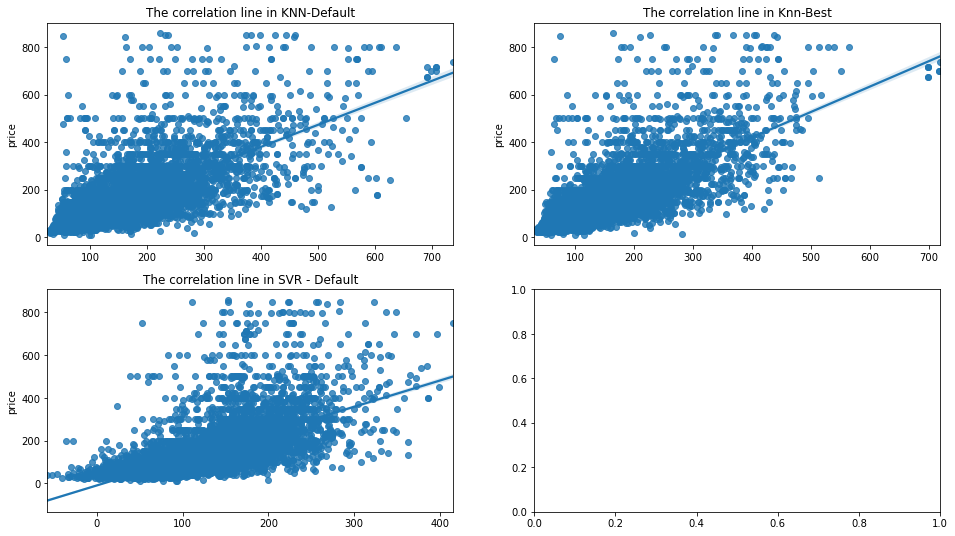

In [ ]:
prediction_dictionaries['SVR - Default'] = preds_svr
plot_all_r2()

As the graph shows there is a correlation between predictions and the actual values. It means model predictions consistent with the actual values. The other comment is that the line in KNN_best is better than the first model. The reason for that second model checks for more neighbours, therefore the result for the second model is more consistent.

In [ ]:
prediction_list['SVR-Default'] = np.array(preds_svr[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default
Actual Values,,,
91,144.2,180.400000,148.771221
325,107.6,127.666667,99.164106
225,225.0,260.733333,191.131547
145,207.8,174.466667,151.448955
333,162.0,172.666667,201.577687
49,62.4,52.733333,38.464069
210,387.8,360.466667,271.582700
110,167.0,153.066667,155.181123
70,180.0,147.466667,171.211842


In [ ]:
error_list['SVR Default'] = [mse_svr, r2_svr]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323


The numbers are slightly worse than the KNN with best performance. Numbers are not bad, but let's see if we can improve the performance with hyperparameter tuning.

##### APPLY HYPERPARAMETER TUNING AND CROSS VALIDATION

The parameters for the Linear SVR:



*   **loss:**  Specifies the loss function (Either L1 Loss or l2 loss)
*   **C:** Regularization parameter. ('C': [0.1, 1, 10, 100, 1000])


*   **dual:** dual or primal optimization problem. (Either True or False)


What we are going to do:



*   Use grid search to fit all those parameters
*   In each iteration use 5 cross validation points

In [ ]:
param_grid = {'C': [0.1, 1, 10, 100, 1000],
              'loss': ['epsilon_insensitive', 'squared_epsilon_insensitive'],
              'dual': [True, False],
              'tol': [0.0001, 0.00001]}

grid = GridSearchCV(LinearSVR(), param_grid, refit = True, verbose = 10, n_jobs=-1, cv=5,scoring="neg_mean_squared_error")

grid.fit(X, y)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done   5 tasks      | elapsed:    0.4s
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.6s
[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed:   35.1s
[Parallel(n_jobs=-1)]: Done  24 tasks      | elapsed:   35.2s
[Parallel(n_jobs=-1)]: Done  33 tasks      | elapsed:   35.9s
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:   37.6s
[Parallel(n_jobs=-1)]: Done  53 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  77 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  90 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done 105 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 120 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 137 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done 173 tasks      | elapsed:  4

GridSearchCV(cv=5, estimator=LinearSVR(), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10, 100, 1000], 'dual': [True, False],
                         'loss': ['epsilon_insensitive',
                                  'squared_epsilon_insensitive'],
                         'tol': [0.0001, 1e-05]},
             scoring='neg_mean_squared_error', verbose=10)

In [ ]:
print(f"Best parameters are {grid.best_params_}")
print("Best score is {}".format(grid.best_score_ * -1))
print("Best model is {}".format(grid.best_estimator_))
print("scores {}".format(grid.cv_results_['mean_test_score']))

Best parameters are {'C': 1, 'dual': True, 'loss': 'epsilon_insensitive', 'tol': 1e-05}
Best score is 6985.398029441681
Best model is LinearSVR(C=1, tol=1e-05)
scores [  -7084.60553938   -7083.99101889   -7858.16211612   -7859.47705938
              nan              nan   -7857.92827904   -7857.92799013
   -6985.7903364    -6985.39802944  -11817.80502799  -11970.15962648
              nan              nan  -11898.20716112  -11898.1982342
   -7174.02714647   -7179.582721    -15337.75295328  -15457.80271402
              nan              nan  -13111.07624831  -13111.06715955
   -7156.77715841   -7204.10298496 -307019.64106398 -317341.71199875
              nan              nan  -13254.0366469   -13254.0272848
   -7461.54848839   -7506.08578213 -722241.42634911 -714324.86307689
              nan              nan  -13268.58376781  -13268.57440643]


In [ ]:
svr_best = LinearSVR(C=1, dual=True, epsilon=0.0, fit_intercept=True,
          intercept_scaling=1.0, loss='epsilon_insensitive', max_iter=1000,
          random_state=None, tol=0.0001, verbose=0)

svr_best.fit(X_train, y_train)

preds_svr_best = svr_best.predict(X_test)

mse_svr_best = mean_squared_error(preds_svr_best, y_test)
mae_svr_best = mean_absolute_error(preds_svr_best, y_test)
rmse_svr_best = np.sqrt(mse_svr_best)
r2_svr_best = r2_score(y_test, preds_svr_best)

print("Mean Squared Error: {}".format(mse_svr_best))
print("Mean Absolute Error: {}".format(mae_svr_best))
print("Root Mean Absolute Error: {}".format(rmse_svr_best))
print("R2 Score: {}".format(r2_svr_best))

Mean Squared Error: 7375.421522615073
Mean Absolute Error: 47.818717832028355
Root Mean Absolute Error: 85.88027435107013
R2 Score: 0.3978714465062779


The mean squared error is slightly better than the default model. But there is not much difference.

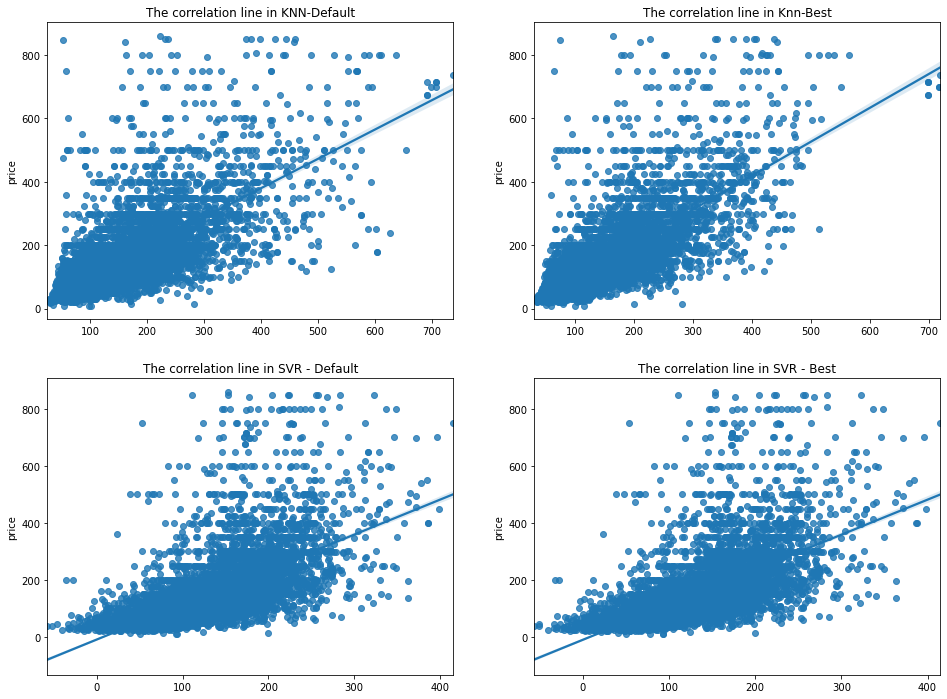

In [ ]:
prediction_dictionaries['SVR - Best'] = preds_svr_best
plot_all_r2()

In [ ]:
prediction_list['SVR-Best'] = np.array(preds_svr_best[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best
Actual Values,,,,
91,144.2,180.400000,148.771221,148.485015
325,107.6,127.666667,99.164106,99.229768
225,225.0,260.733333,191.131547,190.757325
145,207.8,174.466667,151.448955,151.422965
333,162.0,172.666667,201.577687,201.810422
49,62.4,52.733333,38.464069,38.787938
210,387.8,360.466667,271.582700,272.010921
110,167.0,153.066667,155.181123,155.198899
70,180.0,147.466667,171.211842,171.064486


In [ ]:
error_list['SVR Best'] = [mse_svr_best, r2_svr_best]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871


It can be seen that **KNN performed better mostly** (we can see it also from MSE scores). **Hyperparameter tuning for SVR does perform better than the default model.** But there is not much difference. The reason might be that there is no much difference between models in terms of parameters and the difference is not enough to get a huge difference.

#### NEURAL NETWORKS

In [ ]:
!pip install -q git+https://github.com/tensorflow/docs

In [ ]:
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_docs as tfdocs
import tensorflow_docs.plots
import tensorflow_docs.modeling

print(tf.__version__)

2.2.0


In [ ]:
def build_model():
  model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=([X_train.shape[1]])),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)
  ])

  optimizer = tf.keras.optimizers.RMSprop(0.001)

  model.compile(loss='mse',
                optimizer=optimizer,
                metrics=['mae', 'mse'])
  return model

In [ ]:
model = build_model()

history = model.fit(
  X_train, y_train,
  epochs=200, validation_split = 0.2, verbose=0, callbacks=[tfdocs.modeling.EpochDots()])


Epoch: 0, loss:9216.7588,  mae:58.8849,  mse:9216.7588,  val_loss:6046.6104,  val_mae:46.0964,  val_mse:6046.6104,  
....................................................................................................
Epoch: 100, loss:4126.5610,  mae:39.0199,  mse:4126.5610,  val_loss:2675430.2500,  val_mae:59.5978,  val_mse:2675430.2500,  
....................................................................................................

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64)                1664      
_________________________________________________________________
dense_1 (Dense)              (None, 64)                4160      
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 65        
Total params: 5,889
Trainable params: 5,889
Non-trainable params: 0
_________________________________________________________________


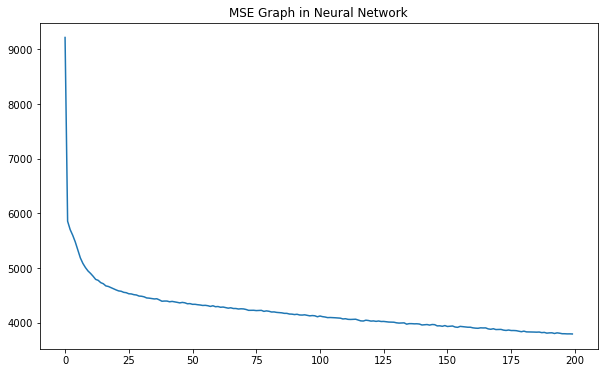

In [ ]:
hist = pd.DataFrame(history.history)
plt.figure(figsize=(10, 6))
plt.plot(hist.mse)
plt.title("MSE Graph in Neural Network")
plt.show()

As we can see from the graph, Neural network tries to reduce te error. Let' see some of the results

Let's see some of the scores of the neural network to see if it performed better than the traditional machine learning models.

In [ ]:
preds_nn = model.predict(X_test)

mse_nn = mean_squared_error(y_test, preds_nn)
mae_nn = mean_absolute_error(y_test, preds_nn)
rmse_nn = np.sqrt(mse_nn)
r2_nn = r2_score(y_test, preds_nn)

print("Mean Squared Error: {}".format(mse_nn))
print("Mean Absolute Error: {}".format(mae_nn))
print("Root Mean Absolute Error: {}".format(rmse_nn))
print("R2 score: {}".format(r2_nn))


Mean Squared Error: 4909.031222098156
Mean Absolute Error: 42.54967815330348
Root Mean Absolute Error: 70.06447903251801
R2 score: 0.5992272631802837


R2 score is almost 0.6 which shows a correlation between predictions and the actual values. Also the mean squared error is slightly less than the previous models which is a good thing because we want the error as minimum as possible.

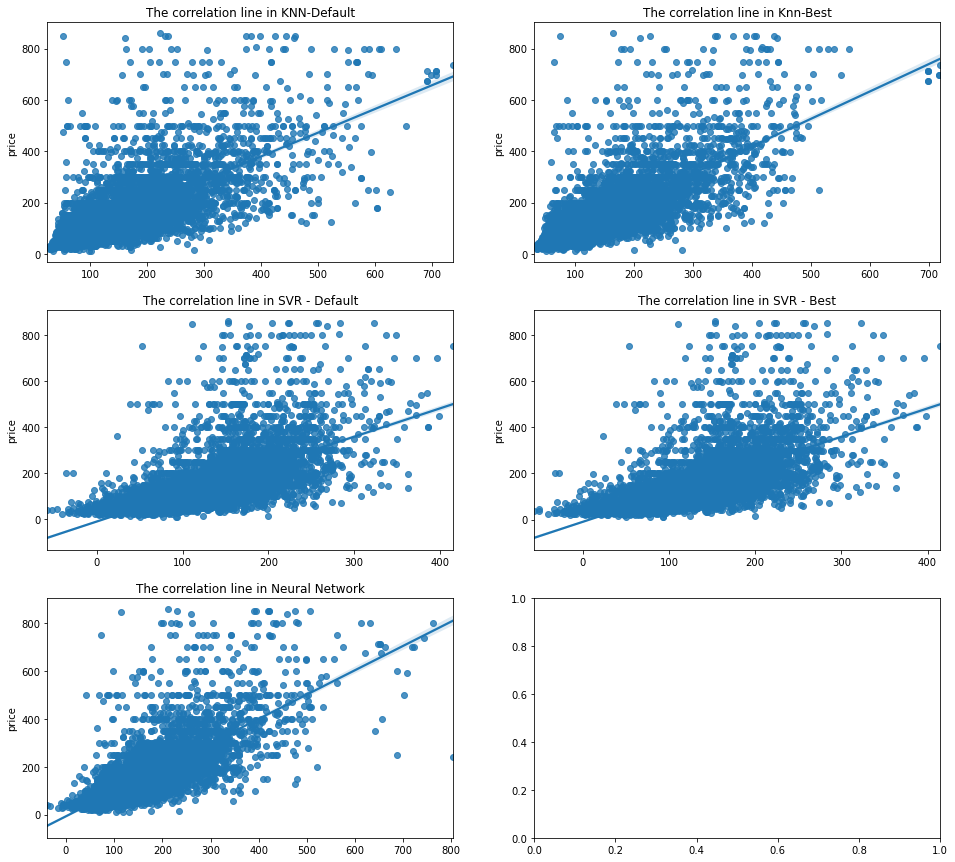

In [ ]:
prediction_dictionaries['Neural Network']  = preds_nn
plot_all_r2()

IT can be seen that neural network is clearly better than the SVR. But, Neural network and the Knn are similar. The correlation line shows that there is a strong correlation between neural network predictions and the actual values. As more data comes the neural network will perform better.

In [ ]:
prediction_list['Neural Network'] = np.array(preds_nn[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best,Neural Network
Actual Values,,,,,
91,144.2,180.400000,148.771221,148.485015,129.761429
325,107.6,127.666667,99.164106,99.229768,118.059692
225,225.0,260.733333,191.131547,190.757325,261.271057
145,207.8,174.466667,151.448955,151.422965,129.726959
333,162.0,172.666667,201.577687,201.810422,240.860382
49,62.4,52.733333,38.464069,38.787938,59.844982
210,387.8,360.466667,271.582700,272.010921,284.603027
110,167.0,153.066667,155.181123,155.198899,148.269470
70,180.0,147.466667,171.211842,171.064486,188.977966


In [ ]:
error_list['Neural Network'] = [mse_nn, r2_nn]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871
Neural Network,4909.031222,0.599227


Neural Network is the best so far

#### DECISION TREE
Decision Tree can be used for classification and regression. Here, we use Decision Tree for regression.

###### BEFORE HYPERPARAMETER TUNING

In [ ]:
from sklearn import tree
from sklearn import metrics

tree_model = tree.DecisionTreeRegressor()
tree_model.fit(X_train, y_train) # x -> features, y->target (price)
tree_model_prediction = tree_model.predict(X_test)

see_result = pd.DataFrame({
    'Actual': y_test,
    'Predicted': tree_model_prediction
    })

tree_mse = metrics.mean_squared_error(y_test, tree_model_prediction)
tree_mae = metrics.mean_absolute_error(y_test, tree_model_prediction)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = metrics.r2_score(y_test, tree_model_prediction)

print("Mean Squared Error: {}".format(tree_mse))
print("Mean Absolute Error: {}".format(tree_mae))
print("Root Mean Absolute Error: {}".format(tree_rmse))
print("R2 score: {}".format(tree_r2))

Mean Squared Error: 8906.974536082475
Mean Absolute Error: 53.35247422680413
Root Mean Absolute Error: 94.3767690487573
R2 score: 0.27283563699079694


The error is 8509 for default Decision Tree Regressor. Although this error is less than Knn's result, it is still more than SVM's result.


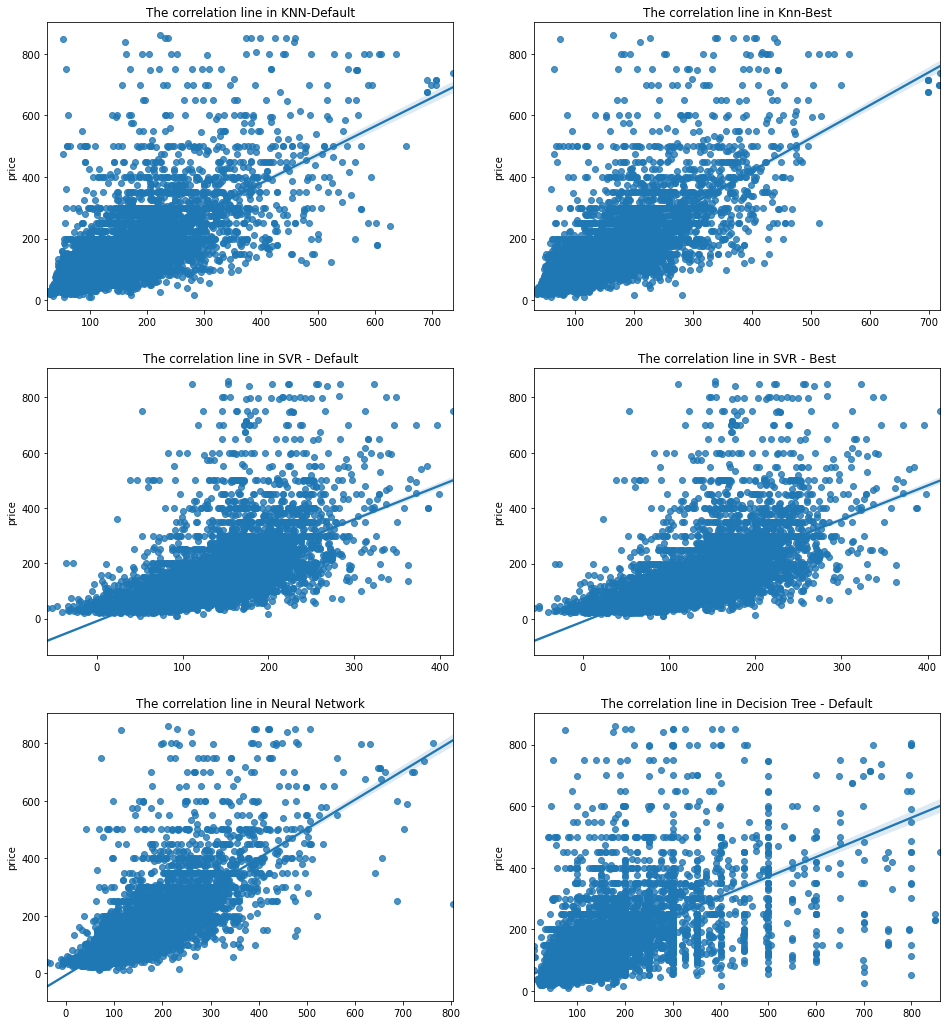

In [ ]:
prediction_dictionaries['Decision Tree - Default'] = tree_model_prediction
plot_all_r2()

In [ ]:
prediction_list['Decision Tree - Default'] = np.array(preds_svr[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best,Neural Network,Decision Tree - Default
Actual Values,,,,,,
91,144.2,180.400000,148.771221,148.485015,129.761429,148.771221
325,107.6,127.666667,99.164106,99.229768,118.059692,99.164106
225,225.0,260.733333,191.131547,190.757325,261.271057,191.131547
145,207.8,174.466667,151.448955,151.422965,129.726959,151.448955
333,162.0,172.666667,201.577687,201.810422,240.860382,201.577687
49,62.4,52.733333,38.464069,38.787938,59.844982,38.464069
210,387.8,360.466667,271.582700,272.010921,284.603027,271.582700
110,167.0,153.066667,155.181123,155.198899,148.269470,155.181123
70,180.0,147.466667,171.211842,171.064486,188.977966,171.211842


In [ ]:
error_list['Decision Tree - Default'] = [tree_mse, tree_r2]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871
Neural Network,4909.031222,0.599227
Decision Tree - Default,8906.974536,0.272836


Decision Tree is the worst so far

##### APPLY HYPERPARAMETER TUNING AND CROSS VALIDATION

Parameters that is used for Decision Tree Regressor:


1.   **max_depth**: The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than min_samples_split samples.
2.   **min_samples_leaf**:The minimum number of samples required to be at a leaf node.
3.   **min_samples_split**:The minimum number of samples required to split an internal node.

[Reference to explanation of parameters](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)


What we are going to do:

1.   Use grid search to fit all those parameters
2.   In each iteration use 5 cross validation points


In [ ]:
parameters = {
    'max_depth': [1, 2, 3, 4, 5, 6, 7, 8],
    'min_samples_leaf': [1, 2, 3, 4, 5],
    'min_samples_split': [2, 3, 4, 5],
}
tree_grid = GridSearchCV(tree_model, parameters, refit = True, verbose = 1, n_jobs=-1, cv=5, scoring="neg_mean_squared_error")
tree_grid.fit(X, y)

Fitting 5 folds for each of 160 candidates, totalling 800 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done 128 tasks      | elapsed:    2.3s
[Parallel(n_jobs=-1)]: Done 668 tasks      | elapsed:   27.4s
[Parallel(n_jobs=-1)]: Done 800 out of 800 | elapsed:   37.9s finished


GridSearchCV(cv=5, estimator=DecisionTreeRegressor(), n_jobs=-1,
             param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 7, 8],
                         'min_samples_leaf': [1, 2, 3, 4, 5],
                         'min_samples_split': [2, 3, 4, 5]},
             scoring='neg_mean_squared_error', verbose=1)

In [ ]:
print(f"Best parameters are {tree_grid.best_params_}")
print("Best MSE is {}".format(tree_grid.best_score_ * -1))

Best parameters are {'max_depth': 7, 'min_samples_leaf': 4, 'min_samples_split': 3}
Best MSE is 5615.575735176118


In [ ]:
tree_model_best = tree.DecisionTreeRegressor(max_depth = 7, min_samples_leaf = 4, min_samples_split = 4)
tree_model_best.fit(X_train, y_train)
tree_model_prediction_best = tree_model_best.predict(X_test)

tree_mse_best = metrics.mean_squared_error(y_test, tree_model_prediction_best)
tree_mae_best = metrics.mean_absolute_error(y_test, tree_model_prediction_best)
tree_rmse_best = np.sqrt(tree_mse_best)
tree_r2_best = metrics.r2_score(y_test, tree_model_prediction_best)

print("Mean Squared Error: {}".format(tree_mse_best))
print("Mean Absolute Error: {}".format(tree_mae_best))
print("Root Mean Absolute Error: {}".format(tree_rmse_best))
print("R2 score: {}".format(tree_r2_best))

Mean Squared Error: 5637.821699190258
Mean Absolute Error: 44.321980009327085
Root Mean Absolute Error: 75.0854293401207
R2 score: 0.5397288935717255


R2 score has significant increase from 0.29 to 0.53.

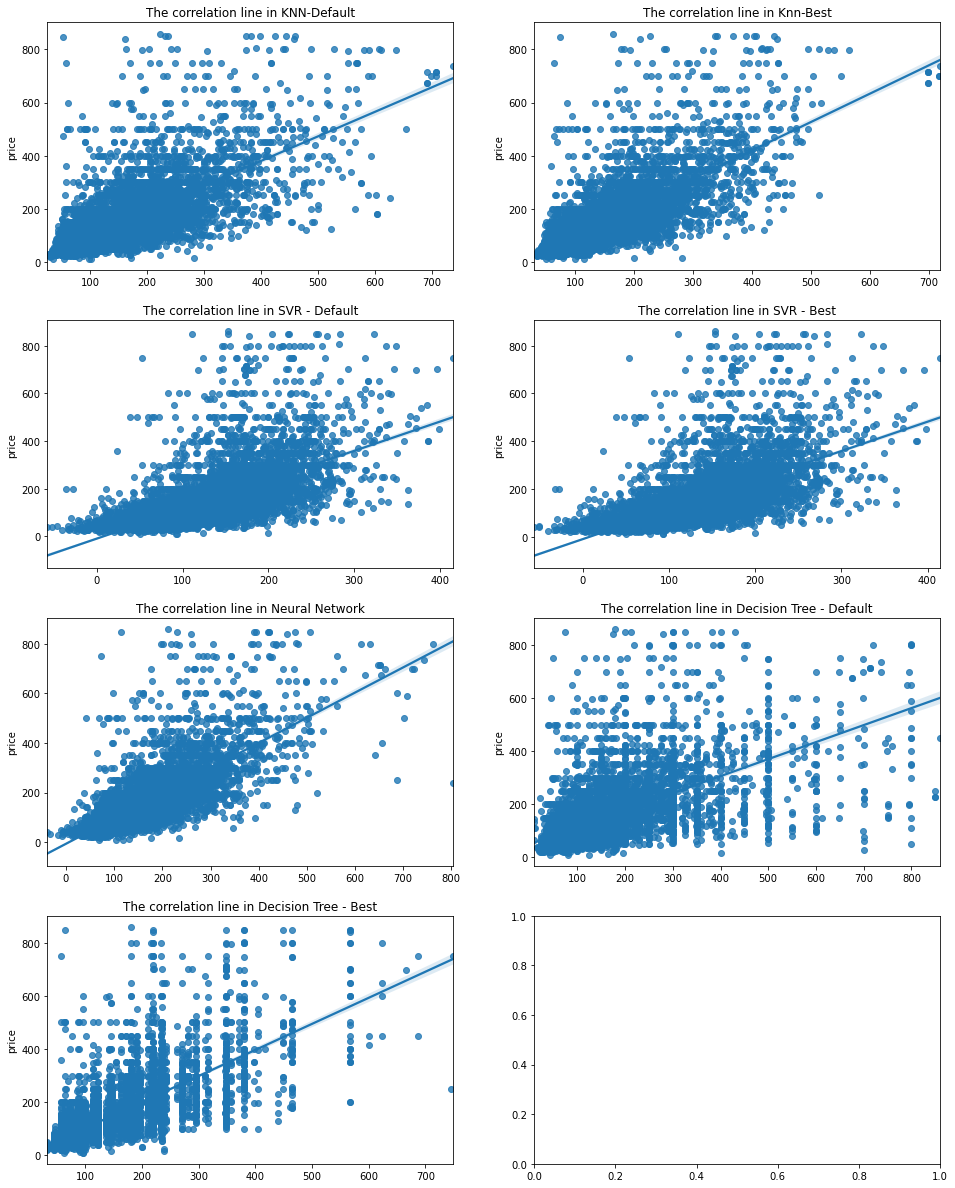

In [ ]:
prediction_dictionaries['Decision Tree - Best'] = tree_model_prediction_best
plot_all_r2()

The group points became less in the best model of Decision Tree. And this is directly affected the performance as we can see correlation line from the graph. And the mean squared error is less in the best model because model performed better. More points collapse around 100-200 price scale. Since the data is mostly around 0-200, the performance is better than the default model of the Decision Tree.

In [ ]:
prediction_list['Decision Tree - Best'] = np.array(preds_svr_best[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best,Neural Network,Decision Tree - Default,Decision Tree - Best
Actual Values,,,,,,,
91,144.2,180.400000,148.771221,148.485015,129.761429,148.771221,148.485015
325,107.6,127.666667,99.164106,99.229768,118.059692,99.164106,99.229768
225,225.0,260.733333,191.131547,190.757325,261.271057,191.131547,190.757325
145,207.8,174.466667,151.448955,151.422965,129.726959,151.448955,151.422965
333,162.0,172.666667,201.577687,201.810422,240.860382,201.577687,201.810422
49,62.4,52.733333,38.464069,38.787938,59.844982,38.464069,38.787938
210,387.8,360.466667,271.582700,272.010921,284.603027,271.582700,272.010921
110,167.0,153.066667,155.181123,155.198899,148.269470,155.181123,155.198899
70,180.0,147.466667,171.211842,171.064486,188.977966,171.211842,171.064486


In [ ]:
error_list['Decision Tree - Best'] = [tree_mse_best, tree_r2_best]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871
Neural Network,4909.031222,0.599227
Decision Tree - Default,8906.974536,0.272836
Decision Tree - Best,5637.821699,0.539729


#### RANDOM FOREST
Random Forest is supervised machine learning algorithms which can be used for regression.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
forest_model = RandomForestRegressor(random_state=42) #n_estimators is 100 by default
forest_model.fit(X_train, y_train)
forest_model_prediction = forest_model.predict(X_test)

forest_mse = metrics.mean_squared_error(y_test, forest_model_prediction)
forest_mae = metrics.mean_absolute_error(y_test, forest_model_prediction)
forest_rmse = np.sqrt(forest_mse)
forest_r2 = metrics.r2_score(y_test, forest_model_prediction)

print("Mean Squared Error: {}".format(forest_mse))
print("Mean Absolute Error: {}".format(forest_mae))
print("Root Mean Absolute Error: {}".format(forest_rmse))
print("R2 score: {}".format(forest_r2))

Mean Squared Error: 4484.5175171134015
Mean Absolute Error: 38.384577319587635
Root Mean Absolute Error: 66.96654028030268
R2 score: 0.6338845125777528


Hyperparameter tuning takes too much time, approximately at least 40 minutes, to finish for random forest model. Therefore, we didn't apply Hyperparameter tuning.

Actually, default random forest gives the best solution among the models that we tried so far. However, it has some performance issues compared to other models.


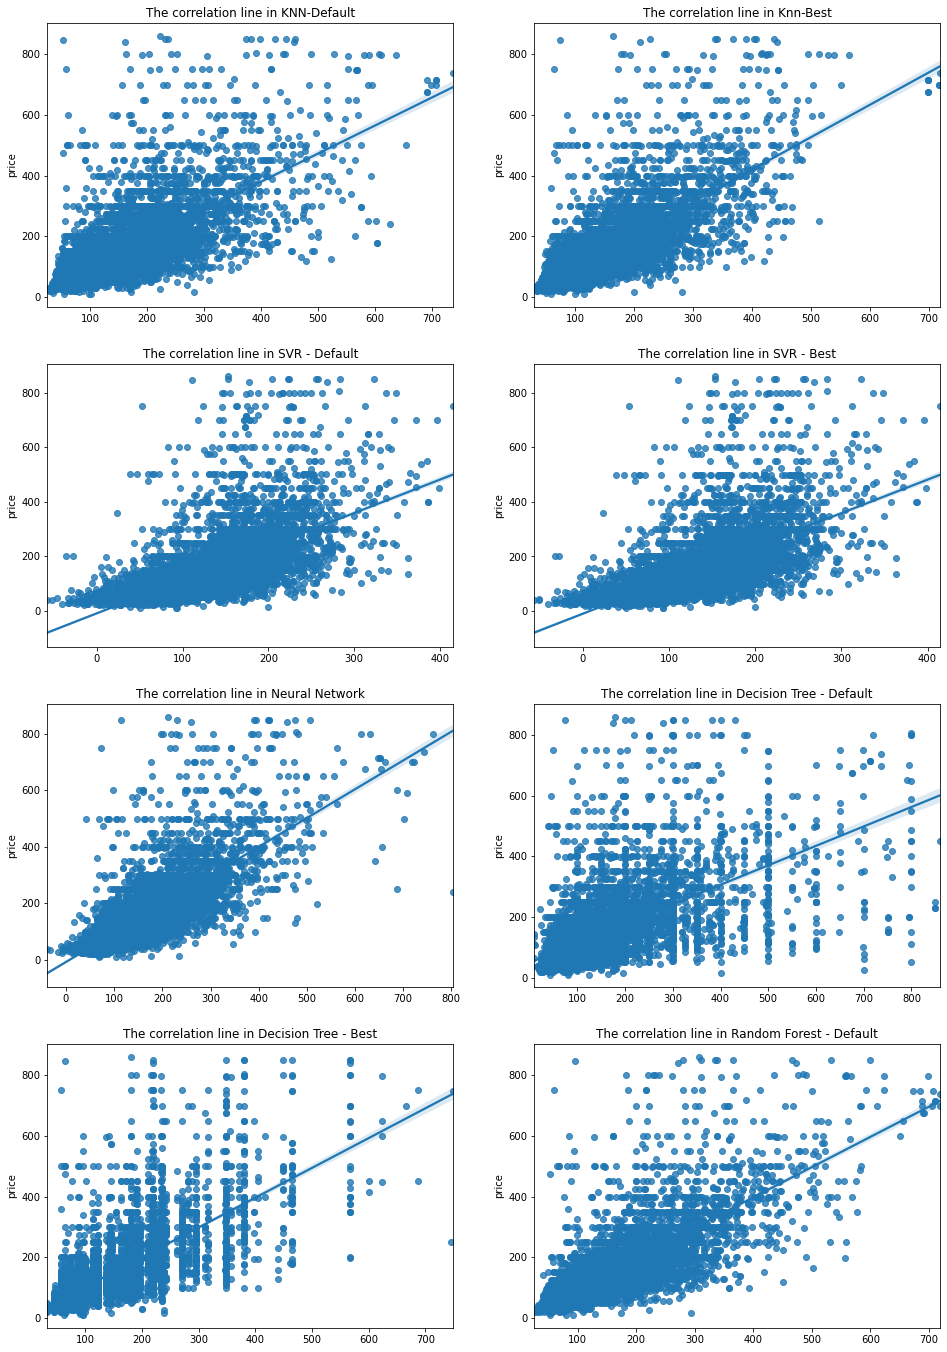

In [ ]:
prediction_dictionaries['Random Forest - Default'] = forest_model_prediction
plot_all_r2()

The points are more spreaded in the Random Forest. Since the Random Forest runs lots of Decision Tree's and get the best tree as the classifier, it is very natural to have a better performance than the Decision Tree. The correlation line performed better than the rest. Since the points are more spreaded and in correct places the mean squared error is less than the rest. Random Forest performed best for now. But let's see other models if we can improve.

In [ ]:
prediction_list['Random Forest - Default'] = np.array(preds_svr[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best,Neural Network,Decision Tree - Default,Decision Tree - Best,Random Forest - Default
Actual Values,,,,,,,,
91,144.2,180.400000,148.771221,148.485015,129.761429,148.771221,148.485015,148.771221
325,107.6,127.666667,99.164106,99.229768,118.059692,99.164106,99.229768,99.164106
225,225.0,260.733333,191.131547,190.757325,261.271057,191.131547,190.757325,191.131547
145,207.8,174.466667,151.448955,151.422965,129.726959,151.448955,151.422965,151.448955
333,162.0,172.666667,201.577687,201.810422,240.860382,201.577687,201.810422,201.577687
49,62.4,52.733333,38.464069,38.787938,59.844982,38.464069,38.787938,38.464069
210,387.8,360.466667,271.582700,272.010921,284.603027,271.582700,272.010921,271.582700
110,167.0,153.066667,155.181123,155.198899,148.269470,155.181123,155.198899,155.181123
70,180.0,147.466667,171.211842,171.064486,188.977966,171.211842,171.064486,171.211842


In [ ]:
error_list['Random Forest - Default'] = [forest_mse, forest_r2]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871
Neural Network,4909.031222,0.599227
Decision Tree - Default,8906.974536,0.272836
Decision Tree - Best,5637.821699,0.539729
Random Forest - Default,4484.517517,0.633885


#### LINEAR REGRESSION

###### BEFORE HYPERPARAMETER TUNING

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score


linear_model = LinearRegression().fit(X_train, y_train)
linear_model_prediction = linear_model.predict(X_test)

linear_mse = metrics.mean_squared_error(y_test, linear_model_prediction)
linear_mae = metrics.mean_absolute_error(y_test, linear_model_prediction)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = metrics.r2_score(y_test, linear_model_prediction)

print("Mean Squared Error: {}".format(linear_mse))
print("Mean Absolute Error: {}".format(linear_mae))
print("Root Mean Absolute Error: {}".format(linear_rmse))
print("R2 score: {}".format(linear_r2))

Mean Squared Error: 6704.483260913462
Mean Absolute Error: 50.00307984797824
Root Mean Absolute Error: 81.88090901372225
R2 score: 0.45264676799308856


The error found in linear regression is 6704. Let's see that does it possible to decrease error by hyperparameter tuning for linear regression.

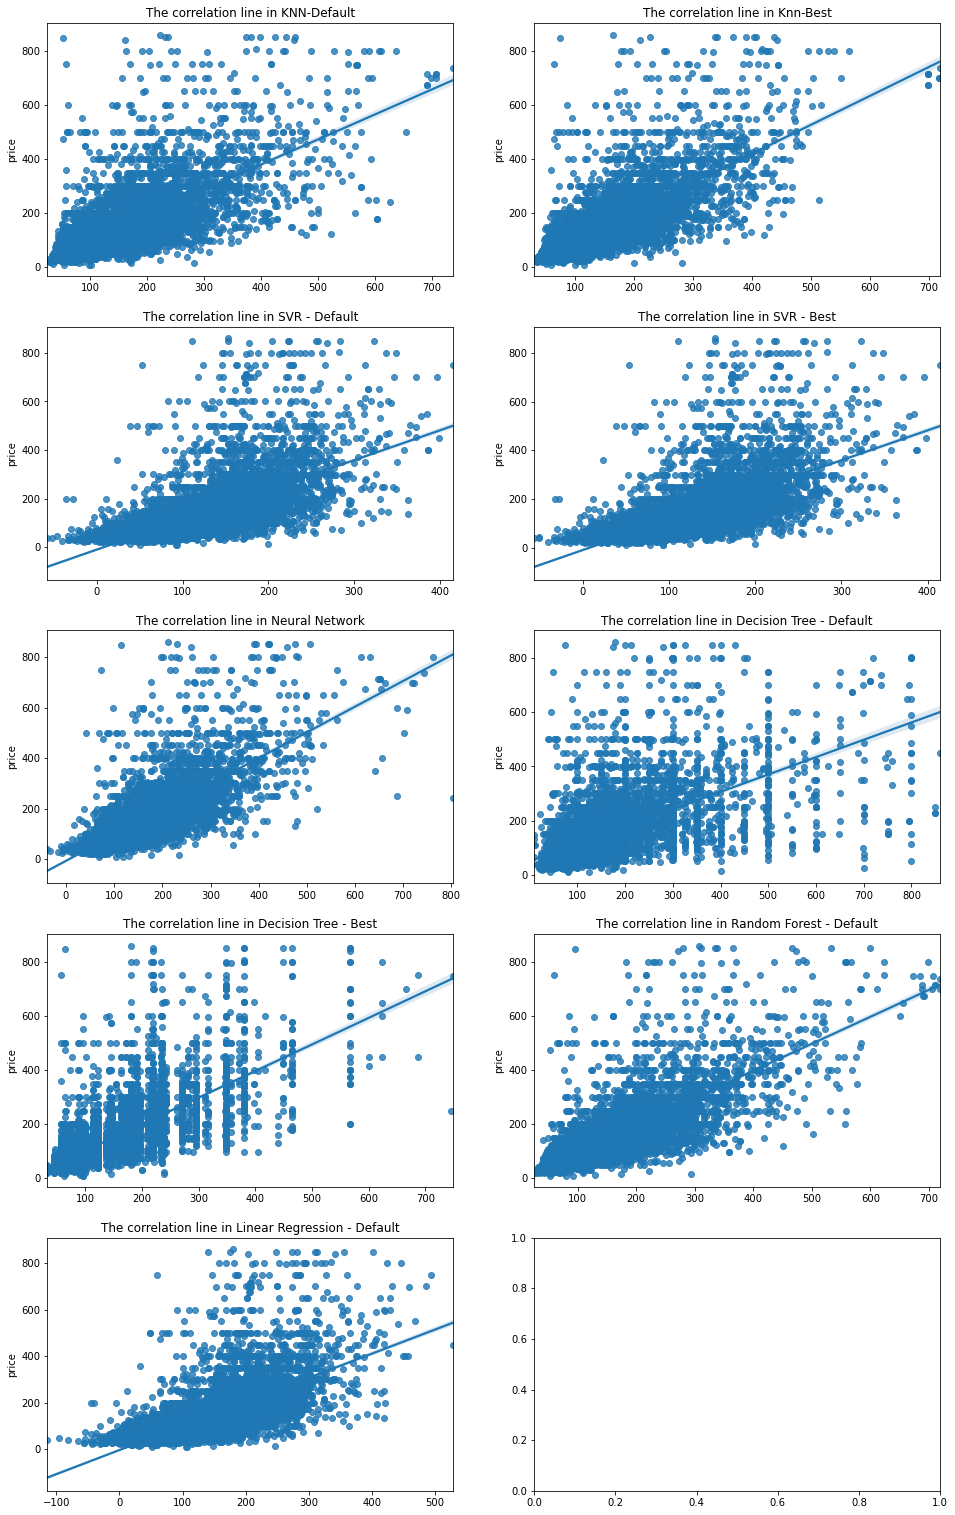

In [ ]:
prediction_dictionaries['Linear Regression - Default'] = linear_model_prediction
plot_all_r2()

In [ ]:
prediction_list['Linear Regression - Default'] = np.array(preds_svr[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best,Neural Network,Decision Tree - Default,Decision Tree - Best,Random Forest - Default,Linear Regression - Default
Actual Values,,,,,,,,,
91,144.2,180.400000,148.771221,148.485015,129.761429,148.771221,148.485015,148.771221,148.771221
325,107.6,127.666667,99.164106,99.229768,118.059692,99.164106,99.229768,99.164106,99.164106
225,225.0,260.733333,191.131547,190.757325,261.271057,191.131547,190.757325,191.131547,191.131547
145,207.8,174.466667,151.448955,151.422965,129.726959,151.448955,151.422965,151.448955,151.448955
333,162.0,172.666667,201.577687,201.810422,240.860382,201.577687,201.810422,201.577687,201.577687
49,62.4,52.733333,38.464069,38.787938,59.844982,38.464069,38.787938,38.464069,38.464069
210,387.8,360.466667,271.582700,272.010921,284.603027,271.582700,272.010921,271.582700,271.582700
110,167.0,153.066667,155.181123,155.198899,148.269470,155.181123,155.198899,155.181123,155.181123
70,180.0,147.466667,171.211842,171.064486,188.977966,171.211842,171.064486,171.211842,171.211842


In [ ]:
error_list['Linear Regression - Default'] = [linear_mse, linear_r2]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871
Neural Network,4909.031222,0.599227
Decision Tree - Default,8906.974536,0.272836
Decision Tree - Best,5637.821699,0.539729
Random Forest - Default,4484.517517,0.633885
Linear Regression - Default,6704.483261,0.452647


##### APPLY HYPERPARAMETER TUNING AND CROSS VALIDATION

We use different techniques for validation our linear regression model called *Ridge*.
   
Since we cannot apply hyperparameter tuning into Linear Regression directly, we will use Ridge in order to apply Hyperparameter tuning.

In [ ]:
from sklearn.linear_model import Ridge

alpha = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 250, 500, 750, 1000, 1500, 2500, 5000, 10000, 100000, 1000000]
param_grid = {
    'alpha': alpha
}

ridge = Ridge(alpha=1).fit(X_train, y_train)
scores = cross_val_score(ridge, X_train, y_train, cv=5, scoring='r2')
scores_mse = cross_val_score(ridge, X_train, y_train, cv=5, scoring='neg_mean_squared_error')

print("CV Mean for Ridge (r2): ", np.mean(scores))
print("CV Mean for Ridge (mse): ", np.mean(scores_mse) * -1)

CV Mean for Ridge (r2):  0.36586777201957094
CV Mean for Ridge (mse):  7223.146833516442


In [ ]:
grid_mse = GridSearchCV(estimator=ridge, param_grid=param_grid, scoring='neg_mean_squared_error', verbose=1, n_jobs=-1)
grid_result_mse = grid_mse.fit(X_train, y_train)

grid_r2 = GridSearchCV(estimator=ridge, param_grid=param_grid, scoring='r2', verbose=1, n_jobs=-1)
grid_result_r2 = grid_r2.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.7s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.


Fitting 5 folds for each of 18 candidates, totalling 90 fits


[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.6s finished


In [ ]:
print('Best Score for mse: ', grid_mse.best_score_ * -1)
print('Best Params for mse: ', grid_mse.best_params_)
print()
print('Best Score for r2: ', grid_r2.best_score_)
print('Best Params for r2: ', grid_r2.best_params_)

Best Score for mse:  6246.9702965914485
Best Params for mse:  {'alpha': 500}

Best Score for r2:  0.45171935704761523
Best Params for r2:  {'alpha': 500}


In [ ]:
ridge_best = Ridge(alpha=500).fit(X_train, y_train)
ridge_best.fit(X_train, y_train)
ridge_pred = ridge_best.predict(X_test)

ridge_mse_best = metrics.mean_squared_error(y_test, ridge_pred)
ridge_mae_best = metrics.mean_absolute_error(y_test, ridge_pred)
ridge_rmse_best = np.sqrt(ridge_mse_best)
ridge_r2_best = metrics.r2_score(y_test, ridge_pred)

print("Mean Squared Error: {}".format(ridge_mse_best))
print("Mean Absolute Error: {}".format(ridge_mae_best))
print("Root Mean Absolute Error: {}".format(ridge_rmse_best))
print("R2 score: {}".format(ridge_r2_best))

Mean Squared Error: 6708.687010265208
Mean Absolute Error: 49.944395977130135
Root Mean Absolute Error: 81.90657489032982
R2 score: 0.45230357438596314


After using Grid Search CV, we found that alpha=500 is the best parameter for Ridge. We can see the effect of Hyperparameter Tuning compared to default Ridge. However, we do not have significant between Ridge and Linear Regression model.

In [ ]:
dict_val = {
    'Linear Model': [linear_r2, linear_mse],
    'Ridge': [ridge_r2_best, ridge_mse_best]
}
res_df_linear_ridge = pd.DataFrame(dict_val, index=['R2', 'MSE'])
res_df_linear_ridge

,Linear Model,Ridge
R2,0.452647,0.452304
MSE,6704.483261,6708.687010


In [ ]:
prediction_dictionaries['Ridge'] = ridge_pred

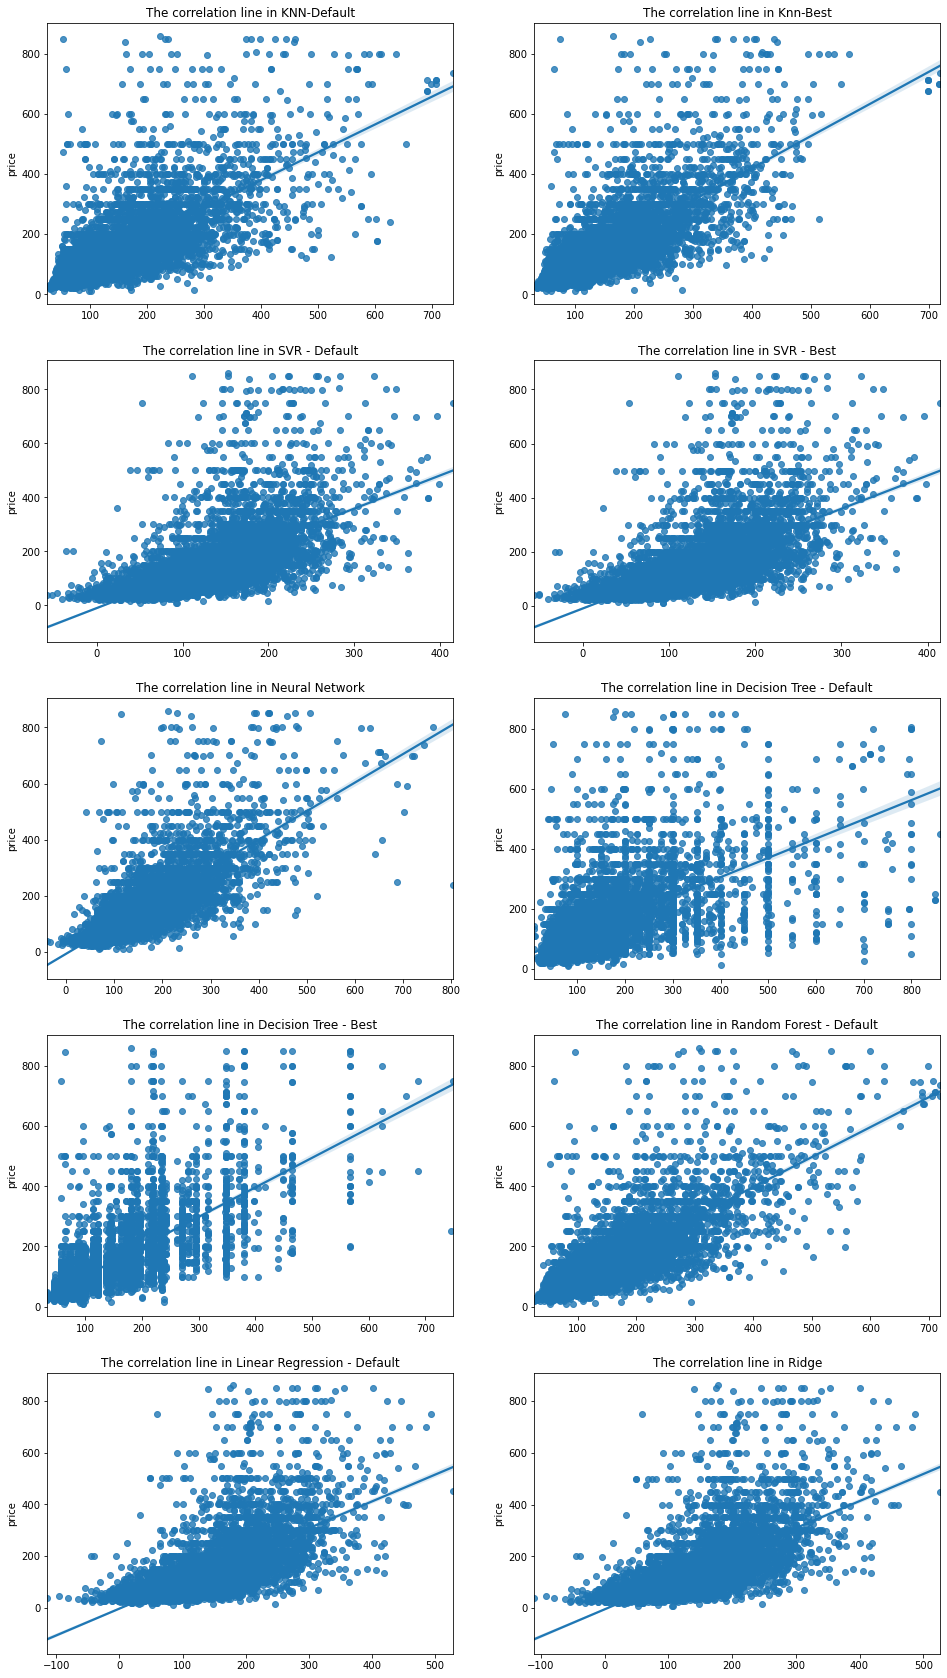

In [ ]:
plot_all_r2()

In [ ]:
prediction_list['Ridge'] = np.array(preds_svr[:20])
prediction_list

,KNN-Default,KNN-Best,SVR-Default,SVR-Best,Neural Network,Decision Tree - Default,Decision Tree - Best,Random Forest - Default,Linear Regression - Default,Ridge
Actual Values,,,,,,,,,,
91,144.2,180.400000,148.771221,148.485015,129.761429,148.771221,148.485015,148.771221,148.771221,148.771221
325,107.6,127.666667,99.164106,99.229768,118.059692,99.164106,99.229768,99.164106,99.164106,99.164106
225,225.0,260.733333,191.131547,190.757325,261.271057,191.131547,190.757325,191.131547,191.131547,191.131547
145,207.8,174.466667,151.448955,151.422965,129.726959,151.448955,151.422965,151.448955,151.448955,151.448955
333,162.0,172.666667,201.577687,201.810422,240.860382,201.577687,201.810422,201.577687,201.577687,201.577687
49,62.4,52.733333,38.464069,38.787938,59.844982,38.464069,38.787938,38.464069,38.464069,38.464069
210,387.8,360.466667,271.582700,272.010921,284.603027,271.582700,272.010921,271.582700,271.582700,271.582700
110,167.0,153.066667,155.181123,155.198899,148.269470,155.181123,155.198899,155.181123,155.181123,155.181123
70,180.0,147.466667,171.211842,171.064486,188.977966,171.211842,171.064486,171.211842,171.211842,171.211842


In [ ]:
error_list['Ridge'] = [ridge_mse_best, ridge_r2_best]
error_list.T

,Mean Squared Error,R2 Score
KNN Default,5661.974049,0.537757
MSE KNN-Best,5023.747697,0.589862
SVR Default,7369.896187,0.398323
SVR Best,7375.421523,0.397871
Neural Network,4909.031222,0.599227
Decision Tree - Default,8906.974536,0.272836
Decision Tree - Best,5637.821699,0.539729
Random Forest - Default,4484.517517,0.633885
Linear Regression - Default,6704.483261,0.452647
Ridge,6708.687010,0.452304


#### RESULTS & DISCUSSION

Random Forest model gives us the best score in R2 as well as MSE. However, as we described in Random Forest section, running time of the Random Forest model is slightly more than other models. Neural Network performed similar to Random Forest and two of them performed best among the other models.

If we do not have time restriction, KNN or Neural Network can be used. Both give us noticeable performance and accuracy. If we had more data, neural network would perform better than the current performance

## CONCLUSION




1.   We trained the data in several models with hyperparameter tuning to see best parameters for each model.
2.  In most of the models, they performed similar but neural network performed best.

3. The errors is slightly better than the Kaggle Results.

## WHAT CAN BE DONE TO INCREASE ACCURACY



*   There could be more data.
*   Models can be trained in lots of parameters to see which one is best. Since it took so much time, we did not train in every possible of combination.

## REFERENCES



1.   https://www.airbnb.com/help/article/2503/what-is-airbnb-and-how-does-it-work

2. https://automating-gis-processes.github.io/site/notebooks/L3/nearest-neighbor-faster.html

3. https://data.ny.gov/Transportation/NYC-Transit-Subway-Entrance-And-Exit-Data/i9wp-a4ja/data

4.   http://go.euromonitor.com/rs/805-KOK-719/images/wpTop100Cities19.pdf?mkt_tok=eyJpIjoiTVRsaU5Ua3lObVUwT1RVdyIsInQiOiJ2RWRQREV6S1wvN0U5N0R3aXI2MjZrRmhsRFpRc1RSNFZBUDljXC9wcFBVWmZcL2thaVRSYm5pOHJERVVxcXpTWVNHbUd1SjhHa0NqQ0g4bGk1a2JreDIzME5UbFFrSFpTblhoczVDcm91OXRSZmh4ZVUyc1dyaVlUeFppWHZNT1U5SiJ9

5. https://www.kaggle.com/erikbruin/airbnb-the-amsterdam-story-with-interactive-maps

6. https://public.opendatasoft.com/explore/dataset/airbnb-listings/table/?disjunctive.host_verifications&disjunctive.amenities&disjunctive.features&refine.city=New+York

7. https://towardsdatascience.com/linear-regression-models-4a3d14b8d368

8. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html